# The third-order aperture-mass statistic: every number, checked

This notebook is the companion of the note
`notes/aperture_mass_statistic/aperture_mass_statistic.tex`.  Each section
computes the numbers one part of the note quotes -- filter properties, toy-model
checks, dataset counts, the fiducial Map3 prediction, the TATT operator split,
the triangle identities of the alignment bispectra -- and rebuilds every figure
of the note through the plot-folder contract (`plots/<name>/data.json` plus a
standalone `plot_<name>.py`).

**How to run it.**  Open it from this directory in an activated Cocoa
environment (`source start_cocoa.sh` from `Cocoa/`), then Kernel - Restart and
Run All.  Sections 2, 3, 6, 8 and 9 are toy numerics and run in seconds.
Sections 4, 5 and 7 evaluate the project's Cobaya likelihood (about 25 s per
model evaluation on a laptop) and cache their results under the project's
`chains/` folder, so a rerun is fast; delete the
`chains/aperture_mass_statistic_*.npz` files to force a recomputation.


## 1. Set up Python

Paths, imports and the house figure style.  The thread counts are set before
any compiled code loads: OpenMP threads the compiled projection, while BLAS
(numpy's linear algebra) stays at one thread so results do not depend on the
machine's core count.

In [1]:
import os
# The OpenMP runtime reads OMP_NUM_THREADS when it starts, so the value is
# set before the compiled interface is imported (threads=4 below matches it).
os.environ["OMP_NUM_THREADS"] = "4"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"

import json
import subprocess
import sys
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# Figure style of the whole notebook: the shared plotting functions never
# change rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'

# NOTE = this note's folder (the notebook's starting directory); PROJECT =
# projects/des_3pcf, found by walking up to its first example yaml; COCOA =
# the Cocoa root.  The yaml paths are relative to COCOA, so the notebook
# changes there, like the project's EXAMPLE_EVALUATE1.ipynb.
NOTE = Path.cwd().resolve()
PROJECT = NOTE
while not (PROJECT / "EXAMPLE_EVALUATE1.yaml").exists():
    if PROJECT == PROJECT.parent:
        raise FileNotFoundError("Open this notebook from the note folder, "
                                "projects/des_3pcf/notes/aperture_mass_statistic.")
    PROJECT = PROJECT.parent
COCOA = PROJECT.parents[1]
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(COCOA / "external_modules/code/cosmolike_core"))
os.chdir(COCOA)
print("note    :", NOTE)
print("project :", PROJECT)
print("cocoa   :", COCOA)

note    : /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/notes/aperture_mass_statistic
project : /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf
cocoa   : /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa


Three helpers used everywhere below.

- `report(label, value, note_value)` prints one result: the number this
  notebook computes next to the number the note quotes.  Agreement is read by
  eye, to the digits the note quotes.
- `run_plot(name)` runs the standalone script `plots/<name>/plot_<name>.py`
  (which reads only `plots/<name>/data.json`) and displays the PNG it wrote, so
  every figure shown here is exactly the file the note includes.
- `cached(name, settings, compute)` wraps the expensive likelihood results:
  it reads `chains/aperture_mass_statistic_<name>.npz` if the file exists and
  its stored settings match, computes and writes it otherwise, and raises on a
  settings mismatch instead of silently overwriting.

In [2]:
def report(label, value, note_value):
    """Print one computed number next to the value the note quotes."""
    print(f"{label:58s} notebook: {value}   note: {note_value}")


def run_plot(name):
    """Run plots/<name>/plot_<name>.py and display the PNG it wrote.

    The script reads only its own data.json, so what is shown here is what a
    reader gets by running the script alone (the plot-folder contract).
    """
    folder = NOTE / "plots" / name
    subprocess.run([sys.executable, f"plot_{name}.py"], cwd=folder, check=True)
    display(Image(filename=str(folder / f"{name}.png")))


def cached(name, settings, compute):
    """Read chains/aperture_mass_statistic_<name>.npz or compute and write it.

    Arguments:
      name = the cache's short name (one file per name under chains/).
      settings = a flat dictionary describing what the arrays depend on
        (yaml name, parameter values); stored as a JSON string in the file.
      compute = a function of no arguments returning {key: numpy array}.
    Returns:
      the {key: array} dictionary, from the file or from compute().
    Raises:
      ValueError when the file exists with different settings: delete the
      file to recompute deliberately, never silently overwrite it.
    """
    path = PROJECT / "chains" / f"aperture_mass_statistic_{name}.npz"
    tag = json.dumps(settings, sort_keys=True)
    if path.exists():
        stored = np.load(path, allow_pickle=False)
        if str(stored["settings"]) != tag:
            raise ValueError(f"{path} was written with other settings; "
                             "delete it to recompute.")
        print(f"read {path.name}")
        return {key: stored[key] for key in stored.files if key != "settings"}
    arrays = compute()
    np.savez(path, settings=np.str_(tag), **arrays)
    print(f"wrote {path.name}")
    return arrays

## 2. The compensated filter and the second moment

The note's Section 5 defines the aperture filter (its Eqs. for
$U_R(\theta)$ and $\widehat{U}(\ell R)$) and Section 6 the second moment.
This section checks, numerically:

1. the compensation property $\int d^2\theta\, U_R(\theta) = 0$;
2. the closed Fourier form $\widehat{U}(\ell R) = \frac{1}{2}(\ell R)^2 e^{-(\ell R)^2/2}$ against direct numerical integration of the Bessel transform;
3. the window's peak at $\ell R = \sqrt{2}$ with peak value $1/e$;
4. the white-noise second moment $\langle M_\mathrm{ap}^2 \rangle = A/(8\pi R^2)$.

The filter radii are the four of the DES Y3 measurement, in arcminutes.

In [3]:
from scipy.integrate import quad
from scipy.special import j0

RADII_ARCMIN = np.array([7.0, 14.0, 25.0, 40.0])
ARCMIN = np.pi / (180.0 * 60.0)          # one arcminute in radians
RADII = RADII_ARCMIN * ARCMIN            # the radii in radians


def filter_u(theta, radius):
    """The compensated aperture filter U_R(theta), both in radians."""
    x2 = (theta / radius) ** 2
    return (1.0 - 0.5 * x2) * np.exp(-0.5 * x2) / (2.0 * np.pi * radius ** 2)


def filter_q(theta, radius):
    """The matching tangential-shear weight Q_R(theta)."""
    x2 = (theta / radius) ** 2
    return theta ** 2 * np.exp(-0.5 * x2) / (4.0 * np.pi * radius ** 4)


def filter_uhat(ell, radius):
    """The closed-form Fourier window of U_R."""
    x2 = (ell * radius) ** 2
    return 0.5 * x2 * np.exp(-0.5 * x2)


# 1. Compensation: the 2D integral reduces to 2 pi int theta U dtheta.
# quad integrates to 10 radii, far beyond the Gaussian tail.
radius = RADII[1]                        # R = 14 arcmin as the example
compensation = 2.0 * np.pi * quad(
    lambda theta: theta * filter_u(theta, radius), 0.0, 10.0 * radius)[0]
report("compensation integral of U (R = 14')", f"{compensation:.2e}",
       "0 (below 1e-10)")
assert abs(compensation) < 1e-10

# 2. The closed form against the numerical Bessel (Hankel) transform at a
# few multipoles around the window's peak.
worst = 0.0
for ell in [50.0, 200.0, 350.0, 700.0, 1500.0]:
    numerical = 2.0 * np.pi * quad(
        lambda theta: theta * filter_u(theta, radius) * j0(ell * theta),
        0.0, 10.0 * radius, limit=200)[0]
    closed = filter_uhat(ell, radius)
    worst = max(worst, abs(numerical - closed))
report("closed form vs numerical Bessel transform (max |diff|)",
       f"{worst:.2e}", "below 1e-10")
assert worst < 1e-10

# 3. The peak: on a fine grid of ell R, the maximum sits at sqrt(2) with
# value 1/e.
x = np.linspace(0.5, 2.5, 200001)
window = 0.5 * x ** 2 * np.exp(-0.5 * x ** 2)
report("peak position ell R", f"{x[np.argmax(window)]:.4f}",
       f"sqrt(2) = {np.sqrt(2.0):.4f}")
report("peak value", f"{window.max():.4f}", f"1/e = {np.exp(-1.0):.4f}")

compensation integral of U (R = 14')                       notebook: -6.54e-17   note: 0 (below 1e-10)
closed form vs numerical Bessel transform (max |diff|)     notebook: 5.55e-17   note: below 1e-10
peak position ell R                                        notebook: 1.4142   note: sqrt(2) = 1.4142
peak value                                                 notebook: 0.3679   note: 1/e = 0.3679


In [4]:
# 4. The white-noise second moment: with P(ell) = A constant, the note's
# worked example gives <Map^2> = A / (8 pi R^2).  The quadrature below
# evaluates the general formula int dell ell/(2 pi) A Uhat^2 directly.
amplitude = 1.0
for radius_arcmin, radius in zip(RADII_ARCMIN, RADII):
    numerical = quad(
        lambda ell: ell / (2.0 * np.pi) * amplitude
        * filter_uhat(ell, radius) ** 2,
        0.0, 20.0 / radius, limit=400)[0]
    analytic = amplitude / (8.0 * np.pi * radius ** 2)
    report(f"white-noise <Map^2>, R = {radius_arcmin:g}': numeric/analytic",
           f"{numerical / analytic:.6f}", "1")
    assert abs(numerical / analytic - 1.0) < 1e-8

white-noise <Map^2>, R = 7': numeric/analytic              notebook: 1.000000   note: 1
white-noise <Map^2>, R = 14': numeric/analytic             notebook: 1.000000   note: 1
white-noise <Map^2>, R = 25': numeric/analytic             notebook: 1.000000   note: 1
white-noise <Map^2>, R = 40': numeric/analytic             notebook: 1.000000   note: 1


The filter figure of the note (its `plots/aperture_filter`): the real-space
weight scaled by $R^2$ (the shape is common; the amplitude scales as
$1/R^2$) and the Fourier window for the four radii.

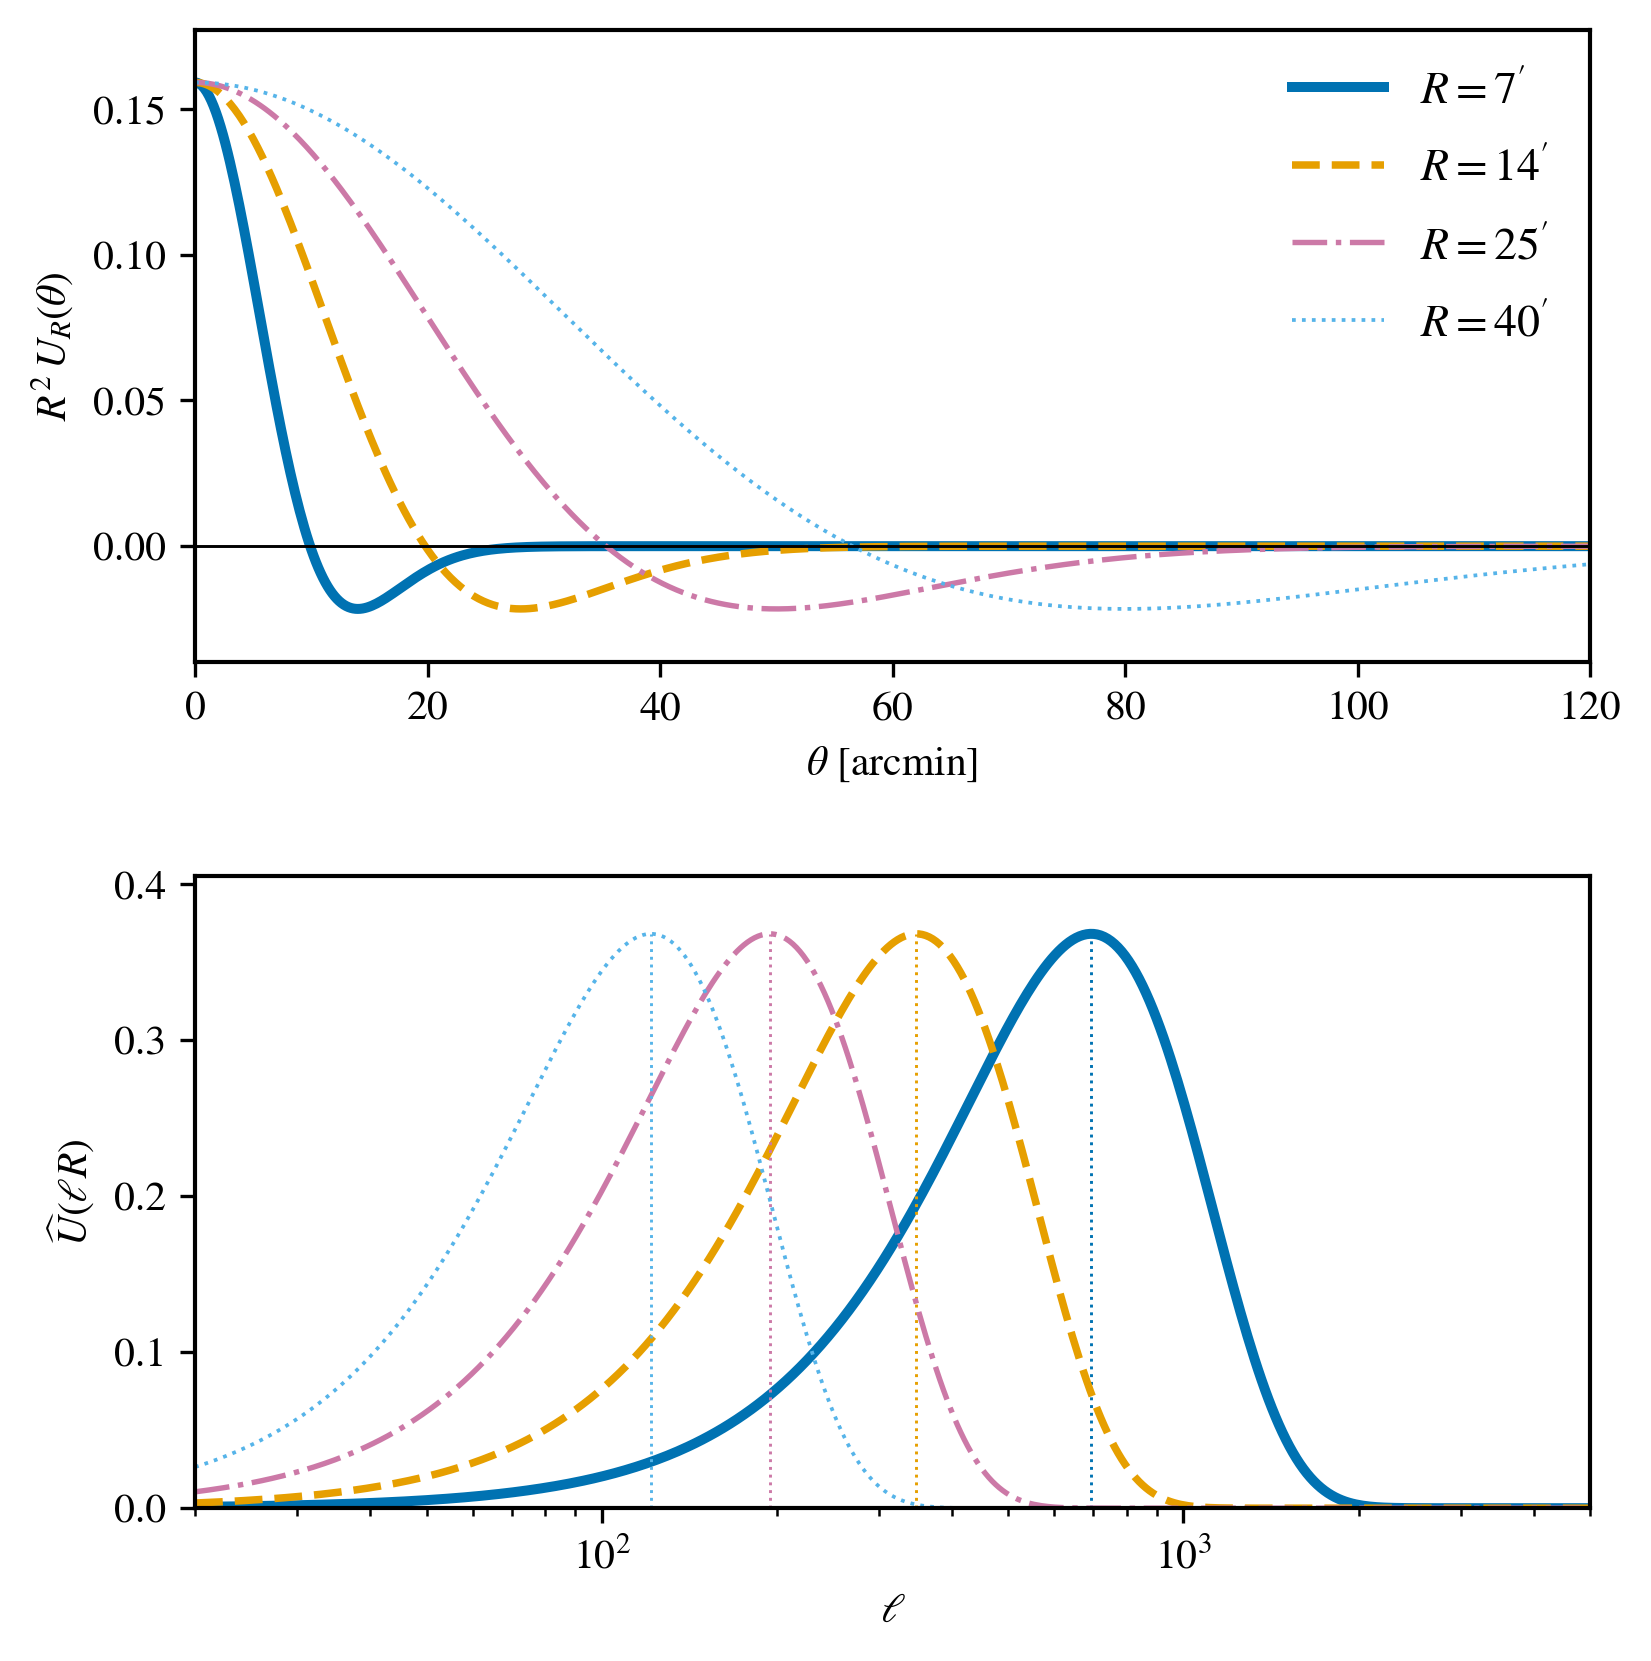

In [5]:
# Export the curves the figure draws, then render it with its standalone
# script.  theta runs to beyond the largest radius's negative trough; ell
# covers the four windows' peaks sqrt(2)/R (about 120 to 700).
theta_arcmin = np.linspace(0.0, 120.0, 601)
u_times_r2 = [filter_u(theta_arcmin * ARCMIN, radius) * radius ** 2
              for radius in RADII]
ell = np.geomspace(20.0, 5000.0, 400)
uhat = [filter_uhat(ell, radius) for radius in RADII]
peak_ell = [float(np.sqrt(2.0) / radius) for radius in RADII]

payload = {
    "about": "The compensated aperture filter of the DES Y3 Map3 "
             "measurement at its four radii: the real-space weight "
             "U_R(theta) times R^2 and the Fourier window Uhat(ell R) = "
             "(ell R)^2/2 exp(-(ell R)^2/2), with each window's peak at "
             "ell = sqrt(2)/R.  Written by the export cell of "
             "aperture_mass_statistic.ipynb, Section 2.",
    "radii_arcmin": RADII_ARCMIN.tolist(),
    "theta_arcmin": theta_arcmin.tolist(),
    "U_times_R2": [curve.tolist() for curve in u_times_r2],
    "ell": ell.tolist(),
    "Uhat": [curve.tolist() for curve in uhat],
    "peak_ell": peak_ell,
}
with open(NOTE / "plots/aperture_filter/data.json", "w") as stream:
    json.dump(payload, stream)
run_plot("aperture_filter")

## 3. A simulated convergence map

The note's Sections 3-7 make five claims that a small simulated map can
check end to end:

1. the shear route and the convergence route to the aperture mass agree
   (the note's $Q$-form equation against its $U$-form definition);
2. a constant mass sheet added to $\kappa$ leaves $M_\mathrm{ap}$ unchanged;
3. a Gaussian field has zero third moment, so the skewness of its
   aperture-mass map is consistent with zero;
4. the measured $\langle M_\mathrm{ap}^2 \rangle$ of the map matches the
   power-spectrum formula evaluated on the map's own Fourier grid;
5. a quadratic non-Gaussian toy field switches the third moment on.

The map is a periodic Gaussian random field on a $512^2$ grid of a
$10^\circ$ box, with a smooth arbitrary spectrum; the shear field is built
from it with the spin-2 phase $\tilde\gamma = e^{2i\beta} \tilde\kappa$.
Periodicity makes the FFT convolutions exact, so the only error left is the
grid quadrature.  This section also exports the note's `gaussian_map` and
`toy_moments` figures.


In [6]:
# ----------------------------------------------------------------------
# The Gaussian convergence map and its shear field.
# ----------------------------------------------------------------------
rng = np.random.default_rng(20261123)    # fixed seed: reproducible numbers
npix = 512
box = 10.0 * np.pi / 180.0               # 10 degrees, in radians
pixel = box / npix

# The flat-sky Fourier grid: one angular frequency vector per FFT mode.
freq = 2.0 * np.pi * np.fft.fftfreq(npix, d=pixel)
ell_x, ell_y = np.meshgrid(freq, freq, indexing="ij")
ell_grid = np.hypot(ell_x, ell_y)

# A smooth positive spectrum (arbitrary shape for the checks): flat on
# large scales, falling as a power beyond ell0, cut well inside Nyquist.
ell0 = 400.0
power = 1.0 / (1.0 + (ell_grid / ell0) ** 2) * np.exp(-(ell_grid / 6000.0) ** 2)
power[0, 0] = 0.0                        # a random field has zero mean

# Draw the field in Fourier space: white Gaussian noise times sqrt(P).
# Building the noise as the FFT of a real map keeps kappa exactly real.
white = np.fft.fft2(rng.standard_normal((npix, npix)))
kappa_ell = white * np.sqrt(power / (pixel ** 2 * npix ** 2))
kappa = np.fft.ifft2(kappa_ell).real
kappa_ell = np.fft.fft2(kappa)           # the exact transform of the map

# The spin-2 phase e^{2 i beta}: beta is the polar angle of ell.  The
# ell = 0 mode has no direction; its shear is set to zero.
with np.errstate(invalid="ignore", divide="ignore"):
    phase = ((ell_x + 1j * ell_y) / ell_grid) ** 2
phase[0, 0] = 0.0
gamma = np.fft.ifft2(phase * kappa_ell)  # complex map gamma_1 + i gamma_2
print("kappa map rms:", f"{kappa.std():.4f}")

kappa map rms: 0.4953


In [7]:
# ----------------------------------------------------------------------
# Check 1: the U route (convergence) against the Q route (tangential
# shear) at 16 aperture centers, R = 14 arcmin.
# ----------------------------------------------------------------------
radius = 14.0 * ARCMIN

# U route: filtering is multiplication by Uhat in Fourier space, so one
# FFT gives Map at every pixel at once.
map_u = np.fft.ifft2(filter_uhat(ell_grid, radius) * kappa_ell).real

# Q route: at each chosen center, sum Q(|dtheta|) * gamma_t over the map
# (the direct definition, no FFT).  The minimum-image wrap keeps every
# separation inside the periodic box.
coords = np.arange(npix) * pixel         # pixel-center coordinates
centers = [(i, j) for i in (64, 192, 320, 448) for j in (64, 192, 320, 448)]
worst = 0.0
for (i, j) in centers:
    dx = coords - coords[i]
    dy = coords - coords[j]
    dx = (dx + 0.5 * box) % box - 0.5 * box   # wrap to [-box/2, box/2)
    dy = (dy + 0.5 * box) % box - 0.5 * box
    sep_x, sep_y = np.meshgrid(dx, dy, indexing="ij")
    sep = np.hypot(sep_x, sep_y)
    # The tangential component at separation vector (sep_x, sep_y):
    # gamma_t = -Re[gamma e^{-2 i phi}], with phi the vector's polar angle.
    with np.errstate(invalid="ignore", divide="ignore"):
        phase2 = ((sep_x + 1j * sep_y) / sep) ** 2
    phase2[i, j] = 0.0                       # Q(0) = 0: the center drops out
    gamma_t = -np.real(gamma * np.conj(phase2))
    map_q = np.sum(filter_q(sep, radius) * gamma_t) * pixel ** 2
    worst = max(worst, abs(map_q - map_u[i, j]))
scale = map_u.std()
report("U route vs Q route, max |difference| / rms(Map)",
       f"{worst / scale:.2e}", "below 1e-2")
assert worst / scale < 1e-2

U route vs Q route, max |difference| / rms(Map)            notebook: 2.09e-15   note: below 1e-2


In [8]:
# ----------------------------------------------------------------------
# Check 2: a constant mass sheet drops out.  Adding kappa_0 changes only
# the ell = 0 mode, which the compensated filter multiplies by
# Uhat(0) = 0; the aperture-mass map must not move.
# ----------------------------------------------------------------------
kappa_sheet = kappa + 0.1
map_sheet = np.fft.ifft2(
    filter_uhat(ell_grid, radius) * np.fft.fft2(kappa_sheet)).real
sheet_change = np.max(np.abs(map_sheet - map_u)) / scale
report("mass sheet kappa_0 = 0.1: max |change| / rms(Map)",
       f"{sheet_change:.2e}", "below 1e-12")
assert sheet_change < 1e-12

# ----------------------------------------------------------------------
# Check 3: Gaussian skewness.  The skewness of the aperture-mass map of a
# Gaussian field is zero in the ensemble; one map scatters around zero.
# The scatter estimate splits the map into 16 blocks and uses the spread
# of their skewnesses over sqrt(16).
# ----------------------------------------------------------------------
values = map_u / scale
skewness = np.mean(values ** 3)
blocks = values.reshape(4, 128, 4, 128).transpose(0, 2, 1, 3).reshape(16, -1)
block_skew = np.mean(blocks ** 3, axis=1)
scatter = block_skew.std() / np.sqrt(16.0)
report("skewness of the Gaussian aperture-mass map",
       f"{skewness:+.4f} +/- {scatter:.4f}", "consistent with 0")
assert abs(skewness) < 4.0 * scatter

mass sheet kappa_0 = 0.1: max |change| / rms(Map)          notebook: 1.53e-15   note: below 1e-12
skewness of the Gaussian aperture-mass map                 notebook: +0.0556 +/- 0.0825   note: consistent with 0


The map figure of the note (its `plots/gaussian_map`): the convergence
map next to its aperture-mass map at $R = 14$ arcmin, each downsampled
$2\times 2$ for storage (the checks above use the full maps).


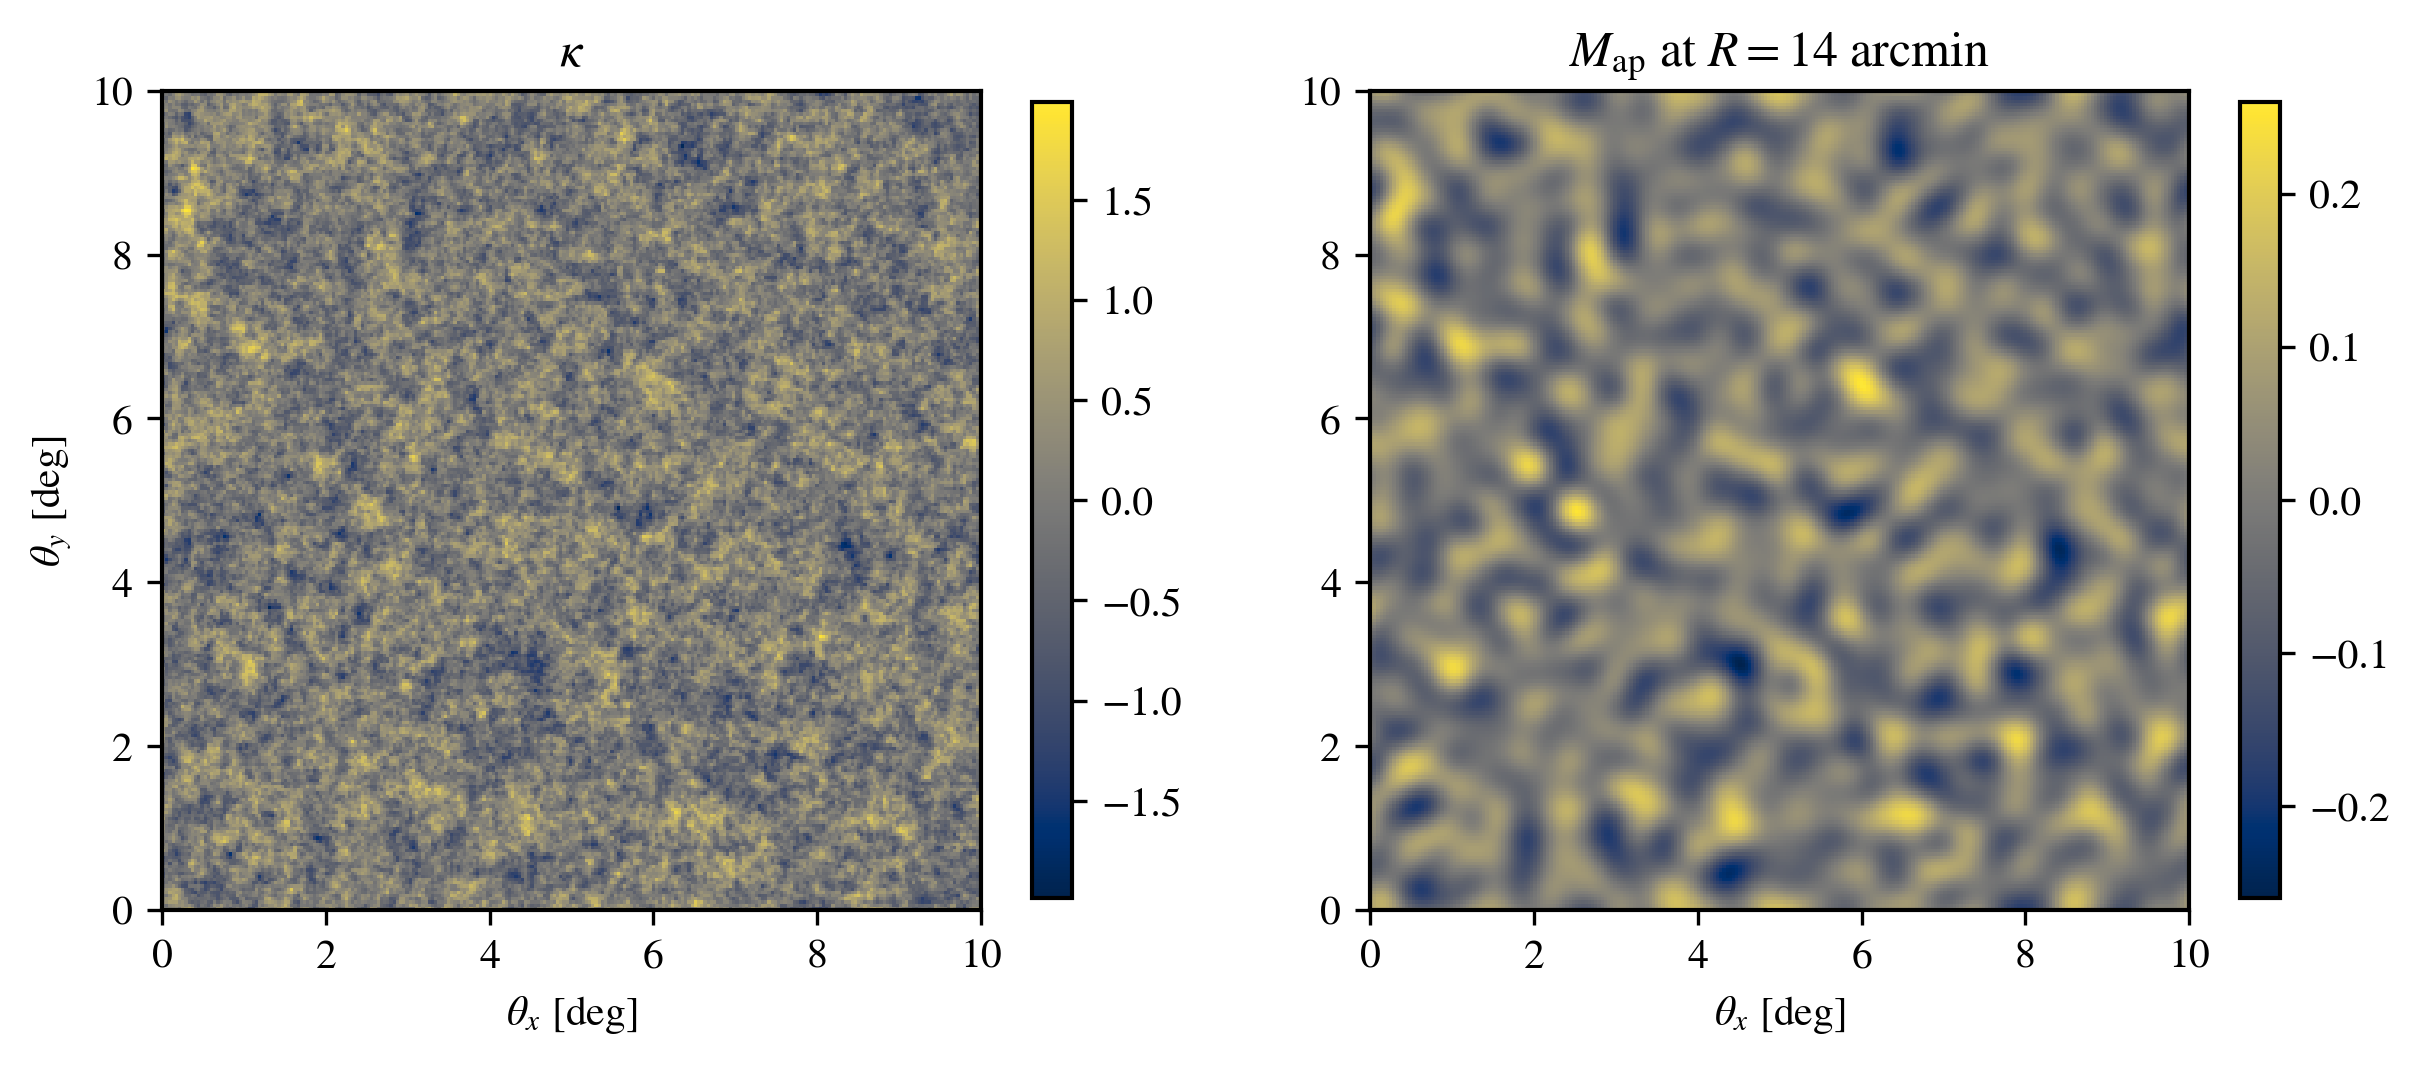

In [9]:
# Export the two maps.  The rounding keeps data.json small without
# visible loss; each array stores about four significant digits.
def rounded(field):
    decimals = int(3 - np.floor(np.log10(field.std())))
    return np.round(field, decimals).tolist()


small_kappa = kappa.reshape(256, 2, 256, 2).mean(axis=(1, 3))
small_map = map_u.reshape(256, 2, 256, 2).mean(axis=(1, 3))
payload = {
    "about": "The simulated Gaussian convergence map of "
             "aperture_mass_statistic.ipynb (Section 3) on a 10 degree "
             "box, and its aperture-mass map at R = 14 arcmin from the "
             "Fourier window (ell R)^2/2 exp(-(ell R)^2/2), both "
             "downsampled 2x2.  Written by the export cell of the "
             "notebook's Section 3.",
    "box_deg": 10.0,
    "radius_arcmin": 14.0,
    "kappa": rounded(small_kappa),
    "map_r14": rounded(small_map),
}
with open(NOTE / "plots/gaussian_map/data.json", "w") as stream:
    json.dump(payload, stream)
run_plot("gaussian_map")


Checks 4 and 5: the measured second moment against the power-spectrum
formula on the map's own Fourier grid, and the third moment of a
deliberately non-Gaussian toy field.  One map carries large sample
variance -- few Fourier modes fit under the window at the largest
radii -- so both checks average 25 independent realizations; the
uncertainty of each mean is the spread over realizations divided by
$\sqrt{25}$.


In [10]:
# ----------------------------------------------------------------------
# Checks 4 and 5, the measurements: 25 realizations of the Gaussian
# field with the same input spectrum, and for each one a quadratic
# non-Gaussian toy, kappa + alpha (kappa^2 - <kappa^2>), the
# one-variable model of the note's Section 7; alpha is half an
# inverse rms, a mild perturbation.  Realization 0 reproduces the map
# drawn above (same seed).
# ----------------------------------------------------------------------
nrealization = 25
alpha = 0.5 / kappa.std()
map2_samples = np.zeros((nrealization, RADII.size))
skew_gauss_samples = np.zeros((nrealization, RADII.size))
skew_toy_samples = np.zeros((nrealization, RADII.size))
windows = [filter_uhat(ell_grid, radius) for radius in RADII]

for realization in range(nrealization):
    rng_r = np.random.default_rng(20261123 + realization)
    white_r = np.fft.fft2(rng_r.standard_normal((npix, npix)))
    field_ell = white_r * np.sqrt(power / (pixel**2 * npix**2))
    field = np.fft.ifft2(field_ell).real
    field_ell = np.fft.fft2(field)
    toy = field + alpha * (field**2 - field.var())
    toy_ell = np.fft.fft2(toy)
    for j, window in enumerate(windows):
        gauss_map = np.fft.ifft2(window * field_ell).real
        toy_map = np.fft.ifft2(window * toy_ell).real
        map2_samples[realization, j] = gauss_map.var()
        skew_gauss_samples[realization, j] = np.mean(
            (gauss_map / gauss_map.std())**3)
        skew_toy_samples[realization, j] = np.mean(
            (toy_map / toy_map.std())**3)

# Check 4: the mean measured <Map^2> against the formula evaluated as
# a sum over the map's own Fourier grid.  The draw gives each mode
# the ensemble power <|kappa_ell|^2> = power/pixel^2, and Parseval
# turns the mode sum into the map variance.
map2_measured = map2_samples.mean(axis=0)
map2_error = map2_samples.std(axis=0) / np.sqrt(nrealization)
map2_predicted = np.array(
    [np.sum(window**2 * power / pixel**2) / npix**4
     for window in windows])
for radius_arcmin, measured, error, predicted in zip(
        RADII_ARCMIN, map2_measured, map2_error, map2_predicted):
    report(f"<Map^2> measured/predicted, R = {radius_arcmin:g}'",
           f"{measured / predicted:.3f} +/- {error / predicted:.3f}",
           "1 within a few uncertainties")
    assert abs(measured / predicted - 1.0) < 4.0 * error / predicted


<Map^2> measured/predicted, R = 7'                         notebook: 1.001 +/- 0.006   note: 1 within a few uncertainties
<Map^2> measured/predicted, R = 14'                        notebook: 1.026 +/- 0.011   note: 1 within a few uncertainties
<Map^2> measured/predicted, R = 25'                        notebook: 1.033 +/- 0.018   note: 1 within a few uncertainties
<Map^2> measured/predicted, R = 40'                        notebook: 1.033 +/- 0.036   note: 1 within a few uncertainties


In [11]:
# ----------------------------------------------------------------------
# Check 5: the third moment switches on with non-Gaussianity.  The
# Gaussian maps' third moments stay consistent with zero; the toy
# maps' are nonzero at every radius, decreasing toward large R as the
# window keeps fewer modes.
# ----------------------------------------------------------------------
skew_gauss = skew_gauss_samples.mean(axis=0)
skew_gauss_error = (skew_gauss_samples.std(axis=0)
                    / np.sqrt(nrealization))
skew_toy = skew_toy_samples.mean(axis=0)
skew_toy_error = skew_toy_samples.std(axis=0) / np.sqrt(nrealization)

gauss_pull = np.abs(skew_gauss) / skew_gauss_error
toy_pull = np.abs(skew_toy) / skew_toy_error
for radius_arcmin, value, error in zip(RADII_ARCMIN, skew_toy,
                                       skew_toy_error):
    print(f"toy third moment, R = {radius_arcmin:3g}': "
          f"{value:+.3f} +/- {error:.3f}")
report("Gaussian maps' third moment, max |value|/uncertainty",
       f"{gauss_pull.max():.1f}", "below 4")
report("toy third moment, |value|/uncertainty at R = 7' and 40'",
       f"{toy_pull[0]:.0f} and {toy_pull[-1]:.1f}", "76 and 8.6")
assert gauss_pull.max() < 4.0
assert toy_pull.min() > 5.0


toy third moment, R =   7': +1.165 +/- 0.015
toy third moment, R =  14': +0.860 +/- 0.017
toy third moment, R =  25': +0.562 +/- 0.026
toy third moment, R =  40': +0.336 +/- 0.039
Gaussian maps' third moment, max |value|/uncertainty       notebook: 1.9   note: below 4
toy third moment, |value|/uncertainty at R = 7' and 40'    notebook: 76 and 8.6   note: 76 and 8.6


The toy-moments figure of the note (its `plots/toy_moments`): the
measured variance against the grid prediction, and the third moments of
the Gaussian and non-Gaussian maps.


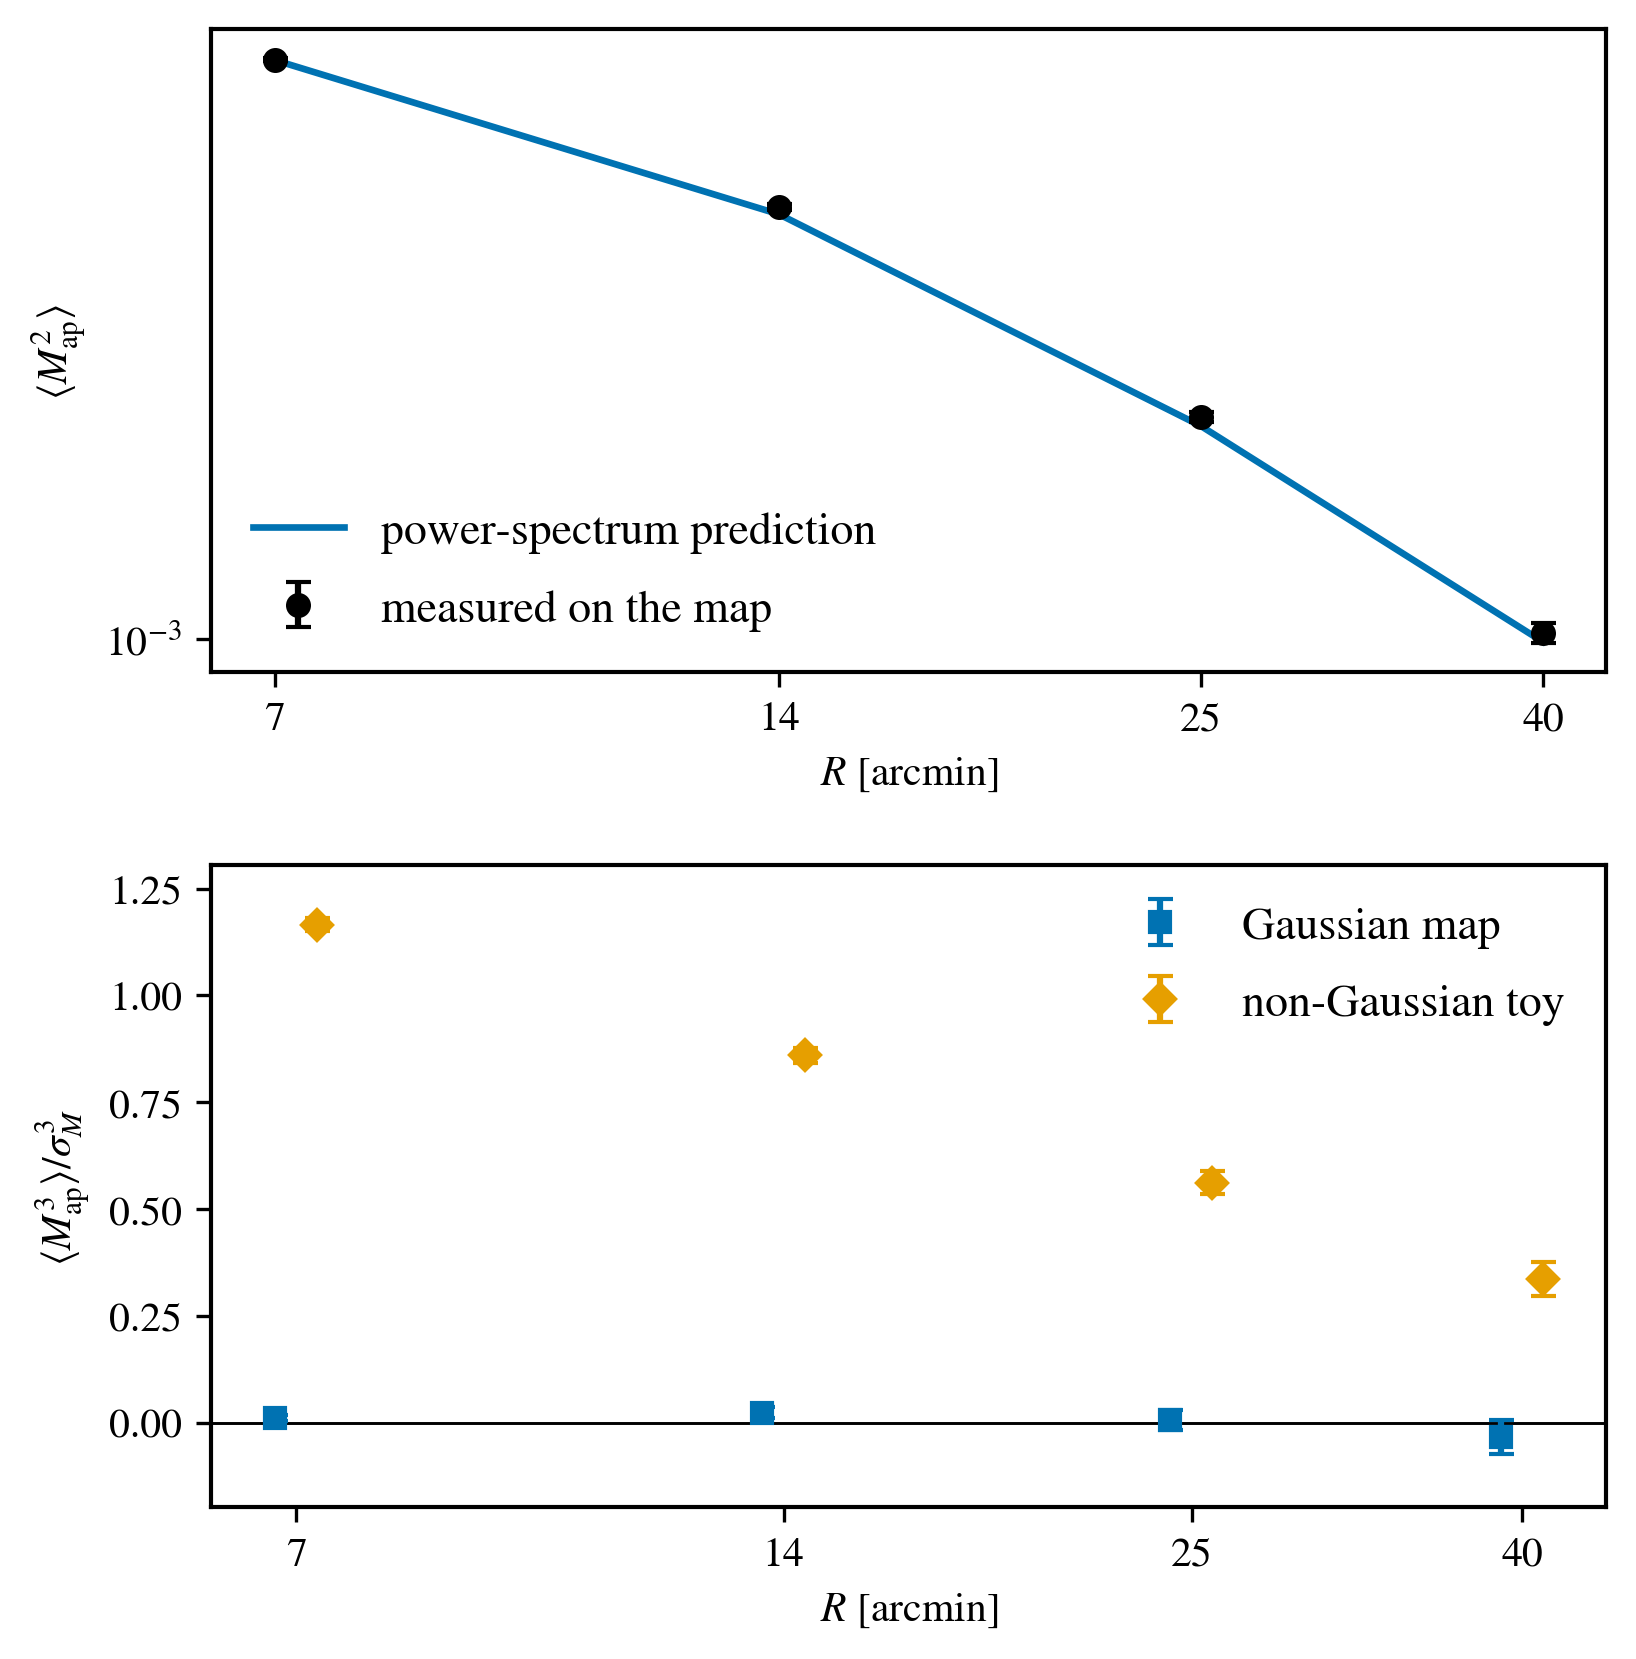

In [12]:
payload = {
    "about": "Aperture-mass moments of the simulated maps of "
             "aperture_mass_statistic.ipynb (Section 3) at the four DES "
             "Y3 radii, each a mean over 25 realizations with the "
             "spread/sqrt(25) uncertainty: the measured <Map^2> of the "
             "Gaussian field against the power-spectrum prediction on "
             "the maps' Fourier grid, and the third moments (scaled by "
             "rms^3) of the Gaussian and of the quadratic non-Gaussian "
             "toy field.  Written by the export cell of the notebook's "
             "Section 3.",
    "radii_arcmin": RADII_ARCMIN.tolist(),
    "map2_measured": map2_measured.tolist(),
    "map2_error": map2_error.tolist(),
    "map2_predicted": map2_predicted.tolist(),
    "skew_gauss": skew_gauss.tolist(),
    "skew_gauss_error": skew_gauss_error.tolist(),
    "skew_toy": skew_toy.tolist(),
    "skew_toy_error": skew_toy_error.tolist(),
}
with open(NOTE / "plots/toy_moments/data.json", "w") as stream:
    json.dump(payload, stream)
run_plot("toy_moments")


## 4. The fiducial point

The note's Section 2 (its Table 1) quotes the `override` block of
`EXAMPLE_EVALUATE1.yaml` and the TATT point of `EXAMPLE_EVALUATE2.yaml`.
This section prints both from the yamls themselves, checks that the project
wrappers read the same values, and computes the derived $\sigma_8$ the note
quotes: the amplitude the project samples is $10^9 A_\mathrm{s}$
(`As_1e9`), and $\sigma_8$ is a CAMB-derived parameter.


In [13]:
from cobaya.yaml import yaml_load_file

info1 = yaml_load_file(str(PROJECT / "EXAMPLE_EVALUATE1.yaml"))
override1 = info1["sampler"]["evaluate"]["override"]
# The quadratic TATT parameters and the expansion history are fixed by
# the yaml rather than sampled; w is the dark-energy equation of state,
# wa its evolution, mnu the neutrino mass sum in eV.
fixed1 = {key: info1["params"][key]
          for key in ("DES_A2_1", "DES_A2_2", "DES_BTA_1",
                      "w", "wa", "mnu")}
print("EXAMPLE_EVALUATE1.yaml override (the fiducial point):")
for key, value in override1.items():
    print(f"  {key:10s} = {value}")
print("fixed by the yaml:")
for key, value in fixed1.items():
    print(f"  {key:10s} = {value}")

info2 = yaml_load_file(str(PROJECT / "EXAMPLE_EVALUATE2.yaml"))
override2 = info2["sampler"]["evaluate"]["override"]
# Keep the short internal names a2/eta2/bta: the cache tags of
# Section 7 use them, so the cached files stay valid.
tatt_point = {"a2": override2["DES_A2_1"],
              "eta2": override2["DES_A2_2"],
              "bta": override2["DES_BTA_1"]}
print("EXAMPLE_EVALUATE2.yaml TATT parameters (the note's Eq. for the "
      "TATT point):", tatt_point)

# The wrappers read the same yaml at import; their module constants
# must match the override exactly.
import cosmolike_des_3pcf_notebook_wrappers as nw
assert nw.omegam == override1["omegam"]
assert nw.omegab == override1["omegab"]
assert nw.H0 == override1["H0"] and nw.ns == override1["ns"]
assert nw.As_1e9 == override1["As_1e9"]
assert nw.A1_FID == [override1["DES_A1_1"], override1["DES_A1_2"]]
print("wrapper constants match the yaml override")


EXAMPLE_EVALUATE1.yaml override (the fiducial point):
  omegam     = 0.289
  omegab     = 0.0463
  H0         = 72.2
  ns         = 0.959
  As_1e9     = 1.8520355901334418
  DES_A1_1   = -0.33
  DES_A1_2   = 2.81
  DES_M1     = -0.0063
  DES_M2     = -0.0198
  DES_M3     = -0.0241
  DES_M4     = -0.0369
  DES_DZ_S1  = 0
  DES_DZ_S2  = 0
  DES_DZ_S3  = 0
  DES_DZ_S4  = 0
fixed by the yaml:
  DES_A2_1   = 0.0
  DES_A2_2   = 0.0
  DES_BTA_1  = 0.0
  w          = -1.0
  wa         = 0.0
  mnu        = 0.06
EXAMPLE_EVALUATE2.yaml TATT parameters (the note's Eq. for the TATT point): {'a2': 0.65, 'eta2': 1.69, 'bta': 0.91}
wrapper constants match the yaml override


In [14]:
# sigma8 is a derived parameter: CAMB computes it from As_1e9 and the
# rest of the cosmology.  One evaluation of a plain Cobaya model built
# from the same yaml returns it (about 25 s); the result is cached.
def compute_sigma8():
    from cobaya.model import get_model
    # A model needs only the parameter, likelihood and theory blocks.
    model_info = {key: info1[key]
                  for key in ("params", "likelihood", "theory")}
    model = get_model(model_info)
    _, derived = model.loglikes(dict(override1), return_derived=True,
                                as_dict=True)
    sigma8 = float(derived["sigma8"])
    # Dropping the model releases CAMB and the compiled likelihood
    # before Section 5 builds the wrappers' own model.
    del model
    return {"sigma8": np.array([sigma8])}


derived = cached(
    name="derived_sigma8",
    settings={"yaml": "EXAMPLE_EVALUATE1.yaml",
              "As_1e9": override1["As_1e9"]},
    compute=compute_sigma8,
)
report("derived sigma8 at the fiducial point",
       f"{derived['sigma8'][0]:.7f}", "0.7865548")


read aperture_mass_statistic_derived_sigma8.npz
derived sigma8 at the fiducial point                       notebook: 0.7865548   note: 0.7865548


## 5. The dataset and the fiducial Map3 prediction

The note's Sections 2, 7, 9 and 10 quote the dataset layout: 200 + 200
$\xi_\pm$ rows and 80 Map3 rows, 20 source-bin triplets, the four radii, the
20 side bins from 0.5 to 80 arcmin with the 9-bin scale cut at 8 arcmin,
$\Delta\ln d$, the 63 opening-angle bins and the transform's multipole caps.
This section evaluates the likelihood once at the fiducial point (cached), reads
all of those numbers back, and draws the note's Map3 figure and triangle-
coverage figure.

In [15]:
# One likelihood evaluation at the EXAMPLE_EVALUATE1 fiducial (about
# 25 s), cached under chains/.  The cache stores the joint vector's row
# kinds and the Map3 grid (radii, triplets, values).
nw.configure(threads=4)


def compute_fiducial():
    labels, vector = nw.datavector()
    # A label is "kind:bin1:bin2:bin3:angles..."; the kind is field one.
    kinds = np.array([label.split(":")[0] for label in labels])
    radii, triplets, values = nw.map3()
    return {"kinds": kinds, "vector": vector, "radii": radii,
            "triplets": triplets, "map3": values}


fiducial = cached(
    name="fiducial",
    settings={"yaml": "EXAMPLE_EVALUATE1.yaml", "point": "override"},
    compute=compute_fiducial,
)
kinds = fiducial["kinds"]
report("xi_plus rows", int(np.sum(kinds == "xip")), 200)
report("xi_minus rows", int(np.sum(kinds == "xim")), 200)
report("Map3 rows", int(np.sum(kinds == "map3")), 80)
report("total rows", kinds.size, 480)
report("filter radii [arcmin]", np.round(fiducial["radii"], 6).tolist(),
       "[7, 14, 25, 40]")
report("source-bin triplets", fiducial["triplets"].shape[0], 20)

# The note's combinatorial count: unordered triples with repetition from
# four source bins, C(4 + 3 - 1, 3) = 20.
from math import comb
report("C(4+3-1, 3)", comb(4 + 3 - 1, 3), 20)

[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


read aperture_mass_statistic_fiducial.npz
xi_plus rows                                               notebook: 200   note: 200
xi_minus rows                                              notebook: 200   note: 200
Map3 rows                                                  notebook: 80   note: 80
total rows                                                 notebook: 480   note: 480
filter radii [arcmin]                                      notebook: [7.0, 14.0, 25.0, 40.0]   note: [7, 14, 25, 40]
source-bin triplets                                        notebook: 20   note: 20
C(4+3-1, 3)                                                notebook: 20   note: 20


In [16]:
# The side-bin facts come from the likelihood defaults the plan is built
# with (likelihood/joint_shear.yaml), reproduced with the same arithmetic
# as the likelihood's initialize.
defaults = yaml_load_file(str(PROJECT / "likelihood/joint_shear.yaml"))
theta_min = defaults["theta_min_arcmin"]
theta_max = defaults["theta_max_arcmin"]
ntheta = defaults["ntheta"]
cut = defaults["theta_lower_cut_arcmin"]
edges = np.exp(np.linspace(np.log(theta_min), np.log(theta_max), ntheta + 1))
kept = edges[:-1][edges[:-1] >= cut]
dlnt = float(np.log(edges[1] / edges[0]))
report("side bins (theta_min, theta_max, ntheta)",
       (theta_min, theta_max, ntheta), "(0.5, 80, 20)")
report("kept side bins (lower edge >= cut)", kept.size, 9)
report("log side-bin width Delta ln d", f"{dlnt:.4f}",
       "ln(160)/20 = 0.2538")
report("opening-angle bins (phi_bins)", defaults["phi_bins"], 63)
report("transform multipole caps (map_lmax, map_mmax)",
       (defaults["map_lmax"], defaults["map_mmax"]), "(20, 20)")

side bins (theta_min, theta_max, ntheta)                   notebook: (0.5, 80.0, 20)   note: (0.5, 80, 20)
kept side bins (lower edge >= cut)                         notebook: 9   note: 9
log side-bin width Delta ln d                              notebook: 0.2538   note: ln(160)/20 = 0.2538
opening-angle bins (phi_bins)                              notebook: 63   note: 63
transform multipole caps (map_lmax, map_mmax)              notebook: (20, 20)   note: (20, 20)


The fiducial Map3 figure of the note (its `plots/map3_fiducial`): the
prediction against the radius for four representative triplets, scaled by a
power of ten chosen here.  Bins are numbered 1 to 4, low to high redshift.

scale: 10^-9;  drawn triplets: ['(1, 1, 1)', '(1, 1, 4)', '(2, 3, 4)', '(4, 4, 4)']


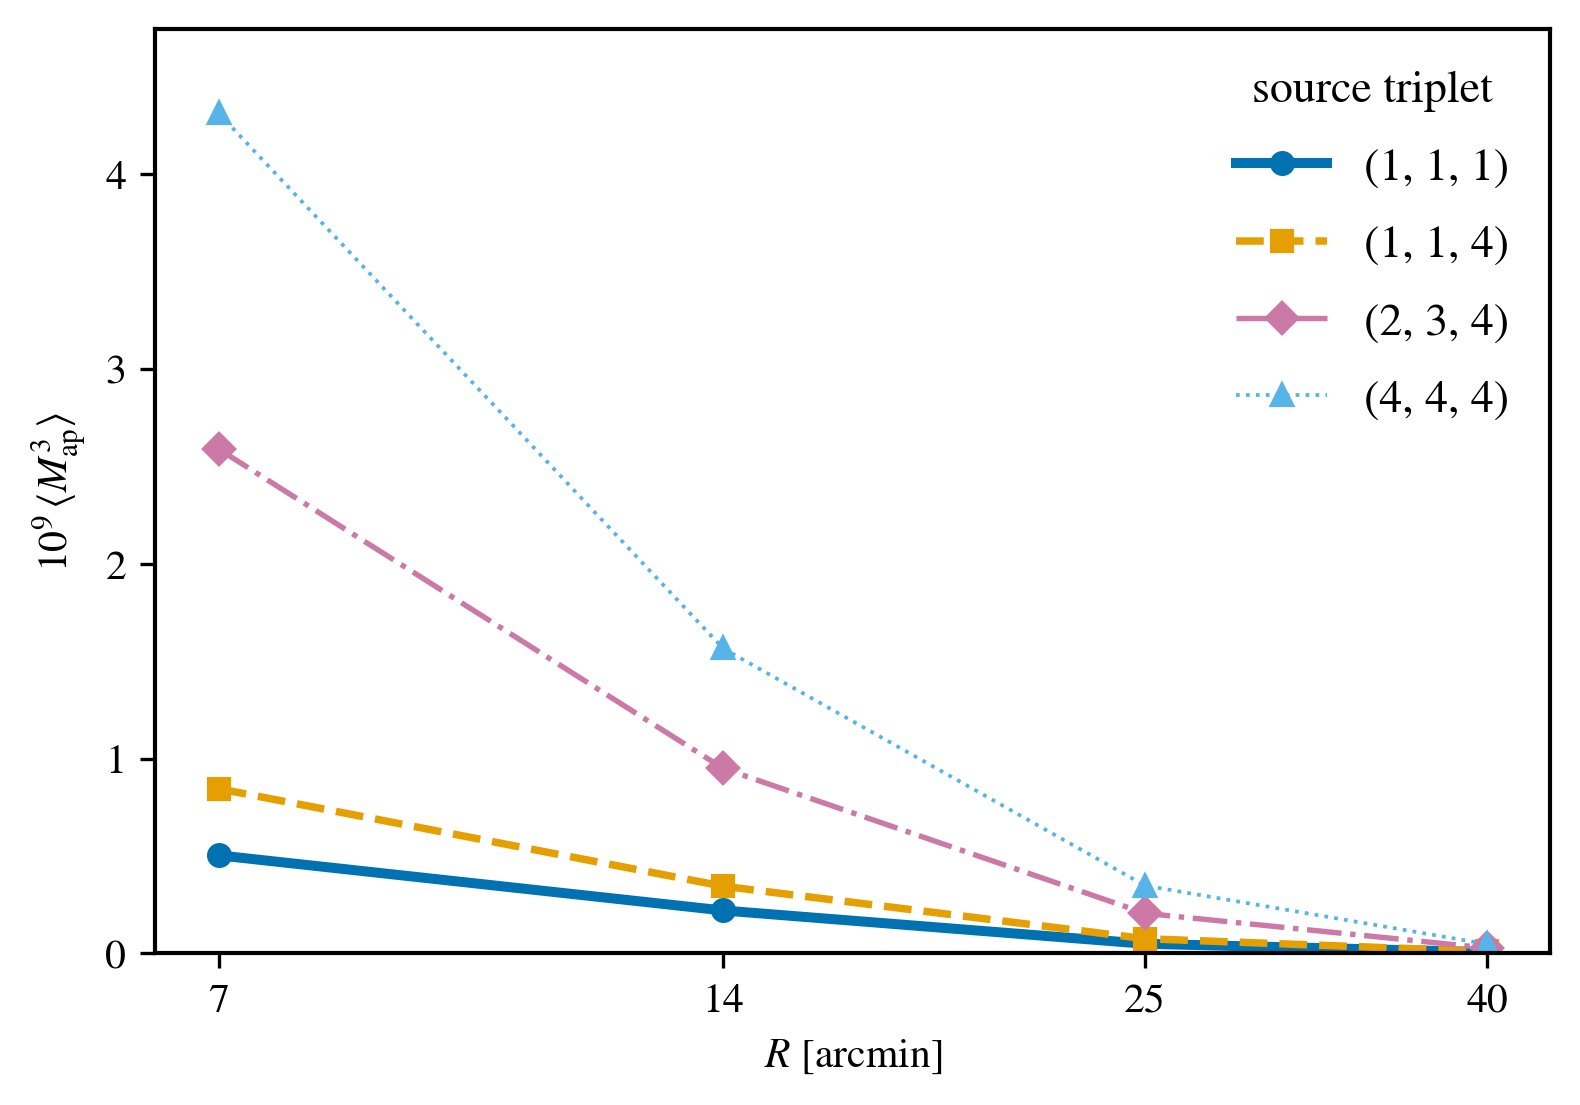

In [17]:
# Pick four triplets that span the range: the lowest and highest
# auto-triplets and two mixed ones.  The dataset's triplets are zero-based.
drawn = [(0, 0, 0), (0, 0, 3), (1, 2, 3), (3, 3, 3)]
triplets = [tuple(int(b) for b in row) for row in fiducial["triplets"]]
rows = [triplets.index(t) for t in drawn]
values = fiducial["map3"].T[rows]        # map3 is [nradius, ntriplet]

# One shared power of ten brings the largest curve to order one.
exponent = int(np.ceil(-np.log10(np.max(np.abs(values)))))
scaled = values * 10.0 ** exponent
labels = ["(" + ", ".join(str(b + 1) for b in t) + ")" for t in drawn]
print("scale: 10^-%d;  drawn triplets:" % exponent, labels)

payload = {
    "about": "Map3 of the des_3pcf likelihood at the EXAMPLE_EVALUATE1 "
             "fiducial, for four source-bin triplets (bins numbered 1-4, "
             "low to high redshift), times 10^%d.  Written by the export "
             "cell of aperture_mass_statistic.ipynb, Section 5, from "
             "nw.map3()." % exponent,
    "radii_arcmin": fiducial["radii"].tolist(),
    "triplet_labels": labels,
    "scaled_values": scaled.tolist(),
    "ylabel": r"$10^{%d}\, \langle M_{\mathrm{ap}}^3 \rangle$" % exponent,
}
with open(NOTE / "plots/map3_fiducial/data.json", "w") as stream:
    json.dump(payload, stream)
run_plot("map3_fiducial")

The triangle-coverage figure of the note (its `plots/triangle_coverage`):
the side plane of the SAS grid, the kept block and the aperture radii.

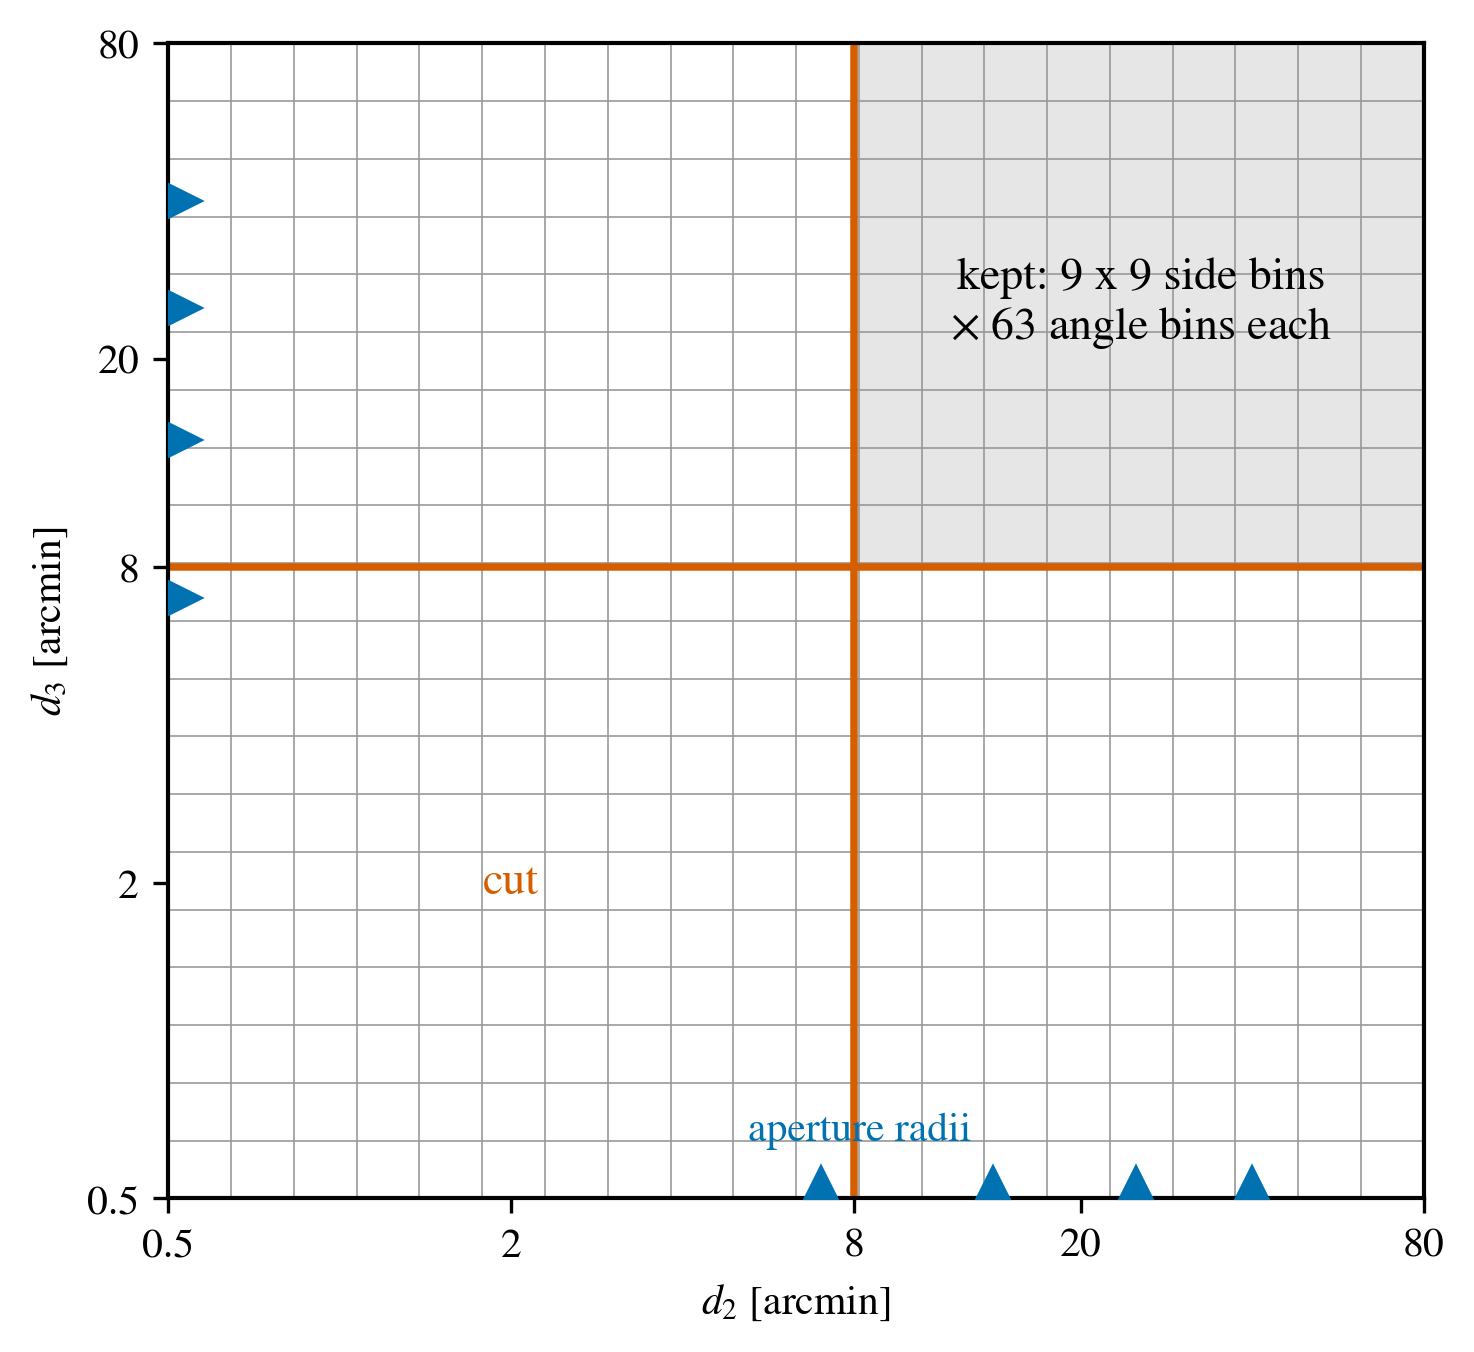

In [18]:
payload = {
    "about": "The side plane (d2, d3) of the SAS triangle grid of the DES "
             "Y3 Map3 rows: 20 logarithmic side bins from 0.5 to 80 arcmin, "
             "the 9 x 9 block kept by the 8 arcmin lower-edge cut (each "
             "pair with 63 opening-angle bins), and the four aperture "
             "radii.  Written by the export cell of "
             "aperture_mass_statistic.ipynb, Section 5, from the "
             "likelihood/joint_shear.yaml keys.",
    "edges_arcmin": edges.tolist(),
    "cut_arcmin": cut,
    "kept_lower_edges_arcmin": kept.tolist(),
    "radii_arcmin": fiducial["radii"].tolist(),
    "phi_bins": defaults["phi_bins"],
}
with open(NOTE / "plots/triangle_coverage/data.json", "w") as stream:
    json.dump(payload, stream)
run_plot("triangle_coverage")

## 6. Measurement arithmetic

The note's Section 10 quotes the DES Y3 measurement's multipole count: the
LogMultipole estimator with cutoff $n_\mathrm{max} = 100$ keeps the
multipoles $-100, \ldots, +100$.  The likelihood's own transform truncates
at the `map_mmax` printed above; the difference is one of the note's open
items.

In [19]:
n_max = 100
report("LogMultipole multipole values, 2 n_max + 1", 2 * n_max + 1, 201)
report("likelihood transform cap map_mmax", defaults["map_mmax"], 20)

LogMultipole multipole values, 2 n_max + 1                 notebook: 201   note: 201
likelihood transform cap map_mmax                          notebook: 20   note: 20


## 7. The TATT operator split

The note's Section 11 derives the intrinsic-alignment theory.  Its operator
figure shows the split of `nw.map3_components()` at the TATT point of
`EXAMPLE_EVALUATE2.yaml`: five physical operators (gravity-only lensing,
linear alignment, density weighting, tidal torquing, velocity shear) by the
eight placements GGG ... III, for the lowest-redshift triplet, where the
alignment terms are largest.  The velocity-shear amplitude stays zero, as in
the likelihood.  The evaluation plus the component projections are cached.

This section prints the extreme values the note quotes (the range of the
linear-alignment ratio, and each quadratic operator's largest ratio at its
value), and exports the note's `map3_operators` and `ia_placements` figures.


In [20]:
nw.configure(yaml="EXAMPLE_EVALUATE2.yaml", threads=4)


def compute_components():
    result = nw.map3_components(
        triplets=[[0, 0, 0]],
        A2=[tatt_point["a2"], tatt_point["eta2"]],
        BTA=tatt_point["bta"],
    )
    components = result["components"]
    print("alignment record used:", result["ia"])
    return {
        "operators": np.array(components["operators"]),
        "placements": np.array(components["placements"]),
        "values": components["values"],
        "total": components["total"],
        "closure": components["closure"],
        "prediction": result["prediction"],
        "radii": result["rows"].angles[:, 0] / ARCMIN,
    }


split = cached(
    name="components",
    settings={"yaml": "EXAMPLE_EVALUATE2.yaml", "triplet": [0, 0, 0],
              "a2": tatt_point["a2"], "eta2": tatt_point["eta2"],
              "bta": tatt_point["bta"], "velocity_shear": 0.0},
    compute=compute_components,
)
print("operators :", split["operators"].tolist())
print("placements:", split["placements"].tolist())
print("radii     :", np.round(split["radii"], 3).tolist())
# closure = (sum of the 5 x 8 pieces) - (the separately computed total):
# the split must add up to the ordinary prediction.
closure = np.max(np.abs(split["closure"]) / np.abs(split["total"]))
report("operator-split closure, max |sum - total| / |total|",
       f"{closure:.2e}", "below 1e-6")
assert closure < 1e-6

[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


read aperture_mass_statistic_components.npz
operators : ['gravity', 'linear_alignment', 'density_weighting', 'tidal_torque', 'velocity_shear']
placements: ['GGG', 'GGI', 'GIG', 'IGG', 'GII', 'IIG', 'IGI', 'III']
radii     : [7.0, 14.0, 25.0, 40.0]
operator-split closure, max |sum - total| / |total|        notebook: 6.53e-15   note: below 1e-6


velocity-shear contribution at C_t = 0, max |value|        notebook: 0.00e+00   note: 0
linear alignment     / gravity: [0.1088, 0.0927, 0.0866, 0.0854]
density weighting    / gravity: [0.0009, 0.0012, 0.0008, -0.0006]
tidal torquing       / gravity: [0.0052, 0.007, 0.0043, -0.0034]
linear alignment / gravity, min .. max                     notebook: +0.0854 .. +0.1088   note: +0.085 .. +0.11
density weighting, max |ratio| (at R = 14')                notebook: 0.0012   note: 0.0012
tidal torquing, max |ratio| (at R = 14')                   notebook: 0.0070   note: 0.0070


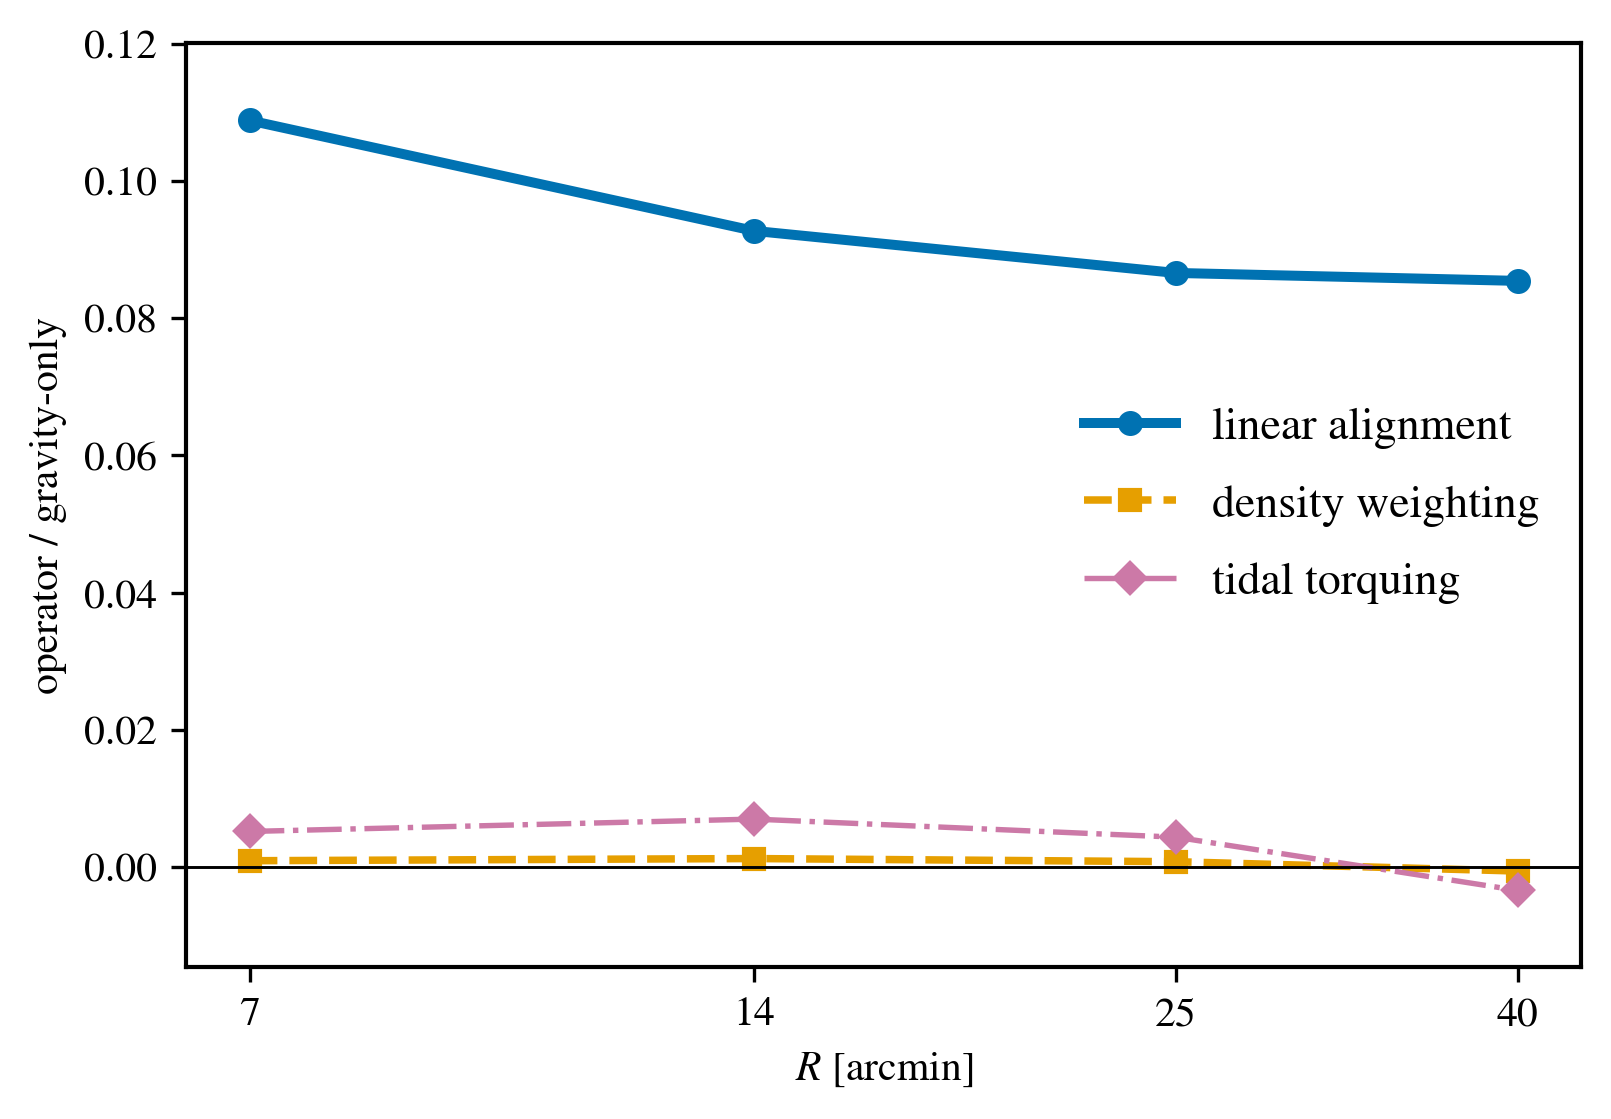

In [21]:
# Each operator's contribution, summed over its eight placements, as a
# fraction of the gravity-only term at the same radius.  The rows arrive
# in dataset order; sort them by radius for the plot.
order = np.argsort(split["radii"])
radii = split["radii"][order]
summed = split["values"].sum(axis=1)[:, order]     # [5, nradius]
gravity = summed[0]
ratios = summed[1:4] / gravity                     # skip gravity and the
velocity = summed[4]                               # zero velocity shear
report("velocity-shear contribution at C_t = 0, max |value|",
       f"{np.max(np.abs(velocity)):.2e}", "0")
names = ["linear alignment", "density weighting", "tidal torquing"]
for name, curve in zip(names, ratios):
    print(f"{name:20s} / gravity:", np.round(curve, 4).tolist())

# The extremes the note quotes, at their printed values: the range of
# the linear-alignment ratio, and each quadratic operator's largest
# |ratio| together with the radius where it occurs.
report("linear alignment / gravity, min .. max",
       f"{ratios[0].min():+.4f} .. {ratios[0].max():+.4f}",
       "+0.085 .. +0.11")
for name, curve, quoted in zip(names[1:], ratios[1:],
                               ["0.0012", "0.0070"]):
    largest = int(np.argmax(np.abs(curve)))
    report(f"{name}, max |ratio| (at R = {radii[largest]:g}')",
           f"{np.abs(curve[largest]):.4f}", quoted)

payload = {
    "about": "The intrinsic-alignment operator split of the Map3 rows of "
             "the lowest-redshift source triplet at the TATT point of "
             "EXAMPLE_EVALUATE2.yaml (a2 = %.2f, eta2 = %.2f, bta = %.2f): "
             "each operator summed over its eight placements, divided by "
             "the gravity-only term, with C_t = 0.  Written by the export "
             "cell of aperture_mass_statistic.ipynb, Section 7, from "
             "nw.map3_components()." % (tatt_point["a2"],
                                        tatt_point["eta2"],
                                        tatt_point["bta"]),
    "radii_arcmin": radii.tolist(),
    "operator_names": names,
    "ratio_to_gravity": ratios.tolist(),
    "ylabel": "operator / gravity-only",
}
with open(NOTE / "plots/map3_operators/data.json", "w") as stream:
    json.dump(payload, stream)
run_plot("map3_operators")


The placements figure of the note (its `plots/ia_placements`): the same
rows resolved along the other axis, operator by placement at
$R = 14$ arcmin.  Gravity lives only in the GGG placement, so its total
there normalizes every marker.


placements: ['GGG', 'GGI', 'GIG', 'IGG', 'GII', 'IIG', 'IGI', 'III']
linear alignment    : largest |placement|/gravity = 2.95e-02 at GIG
density weighting   : largest |placement|/gravity = 3.98e-04 at IGG
tidal torquing      : largest |placement|/gravity = 2.28e-03 at IGG


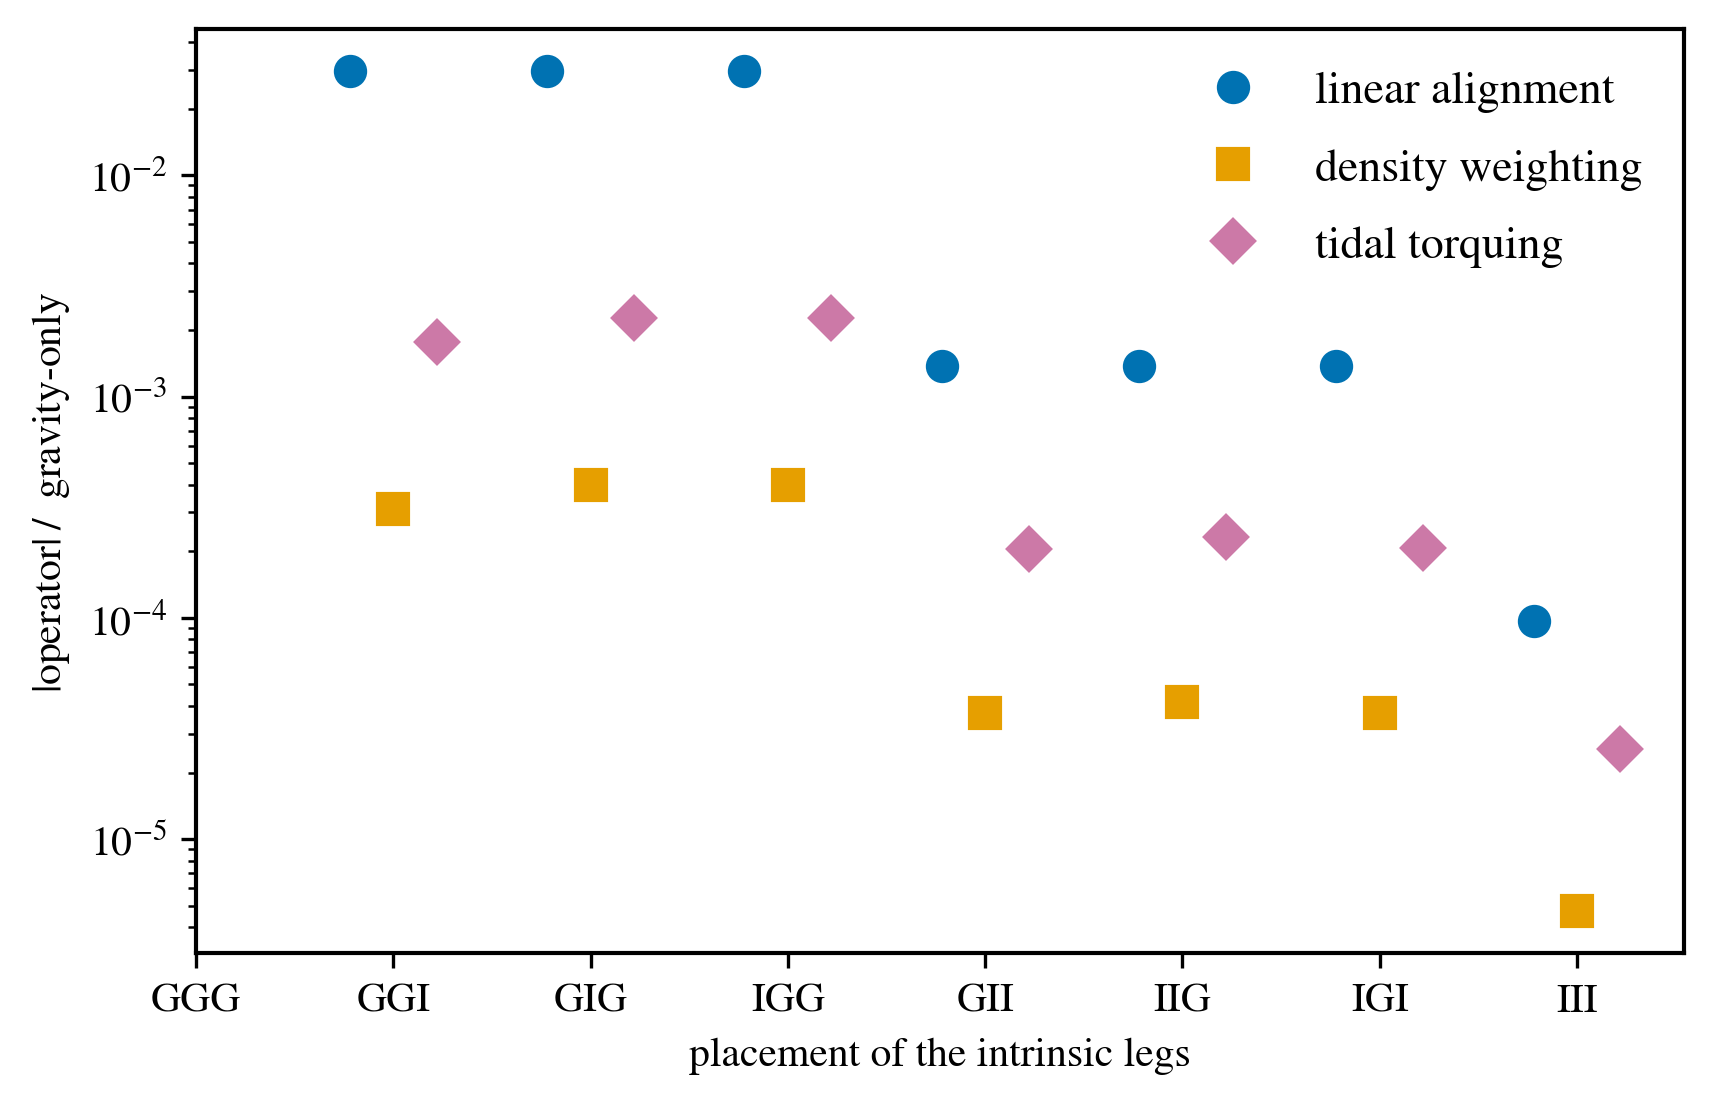

In [22]:
index14 = int(np.argmin(np.abs(split["radii"] - 14.0)))
gravity14 = float(split["values"][0].sum(axis=0)[index14])
placement_ratio = split["values"][1:4, :, index14] / gravity14
placements = [str(name) for name in split["placements"]]
print("placements:", placements)
for name, row in zip(names, placement_ratio):
    largest = int(np.argmax(np.abs(row)))
    print(f"{name:20s}: largest |placement|/gravity = "
          f"{np.abs(row[largest]):.2e} at {placements[largest]}")

payload = {
    "about": "The alignment operators of the lowest-redshift triplet's "
             "Map3 row at R = 14 arcmin, resolved by galaxy placement "
             "and divided by the gravity-only (GGG) term, at the TATT "
             "point of EXAMPLE_EVALUATE2.yaml.  Signed values; the "
             "plot script draws |value| with open markers for negative "
             "entries.  Written by the export cell of "
             "aperture_mass_statistic.ipynb, Section 7, from "
             "nw.map3_components().",
    "placements": placements,
    "operator_names": names,
    "ratio_to_gravity": placement_ratio.tolist(),
}
with open(NOTE / "plots/ia_placements/data.json", "w") as stream:
    json.dump(payload, stream)
run_plot("ia_placements")


## 8. Triangle identities of the alignment bispectra

The note's Section 11 derives the TATT density-density-E bispectrum step
by step and collapses it with a closure identity; this section checks
every arithmetic fact of that derivation, plus the kernel-coverage
numbers of the note's Section 9.  Everything here is plain numpy, no
likelihood evaluation.


In [23]:
# ----------------------------------------------------------------------
# The closure identities: on closed in-plane triangles rotated so the
# third wavevector points along +x,
#   A = (k1.k2)(k1x k2x - k1y k2y) equals Sigma_+/2, and
#   Y = (k1.k2)(k1x k2y + k1y k2x) equals Sigma_x,
# so the note's derived torque line and the printed one agree.
# ----------------------------------------------------------------------
rng_triangles = np.random.default_rng(1123)
k1 = rng_triangles.normal(size=(100000, 2))
k2 = rng_triangles.normal(size=(100000, 2))
k3 = -(k1 + k2)

# Rotate every triangle by minus the angle of k3.
angle3 = np.arctan2(k3[:, 1], k3[:, 0])
cos3, sin3 = np.cos(-angle3), np.sin(-angle3)


def rotate(vectors):
    return np.stack([cos3 * vectors[:, 0] - sin3 * vectors[:, 1],
                     sin3 * vectors[:, 0] + cos3 * vectors[:, 1]],
                    axis=1)


hat1 = rotate(k1)
hat2 = rotate(k2)
hat1 /= np.hypot(hat1[:, 0], hat1[:, 1])[:, None]
hat2 /= np.hypot(hat2[:, 0], hat2[:, 1])[:, None]
dot = np.sum(hat1 * hat2, axis=1)
sigma_plus = (hat1[:, 0]**2 - hat1[:, 1]**2
              + hat2[:, 0]**2 - hat2[:, 1]**2)
sigma_cross = hat1[:, 0] * hat1[:, 1] + hat2[:, 0] * hat2[:, 1]
a_mixed = dot * (hat1[:, 0] * hat2[:, 0] - hat1[:, 1] * hat2[:, 1])
y_mixed = dot * (hat1[:, 0] * hat2[:, 1] + hat1[:, 1] * hat2[:, 0])

report("closure identity A = Sigma_+/2, max |difference|",
       f"{np.max(np.abs(a_mixed - 0.5 * sigma_plus)):.2e}",
       "below 1e-12")
report("closure identity Y = Sigma_x, max |difference|",
       f"{np.max(np.abs(y_mixed - sigma_cross)):.2e}", "below 1e-12")

# The note's assembled torque line C2 (A - Sigma_+/3) against the
# printed C2 (A/2 - Sigma_+/12): identical on every closed triangle.
derived_line = a_mixed - sigma_plus / 3.0
printed_line = 0.5 * a_mixed - sigma_plus / 12.0
report("derived vs printed torque line, max |difference|",
       f"{np.max(np.abs(derived_line - printed_line)):.2e}",
       "below 1e-12")
assert np.max(np.abs(a_mixed - 0.5 * sigma_plus)) < 1e-12


closure identity A = Sigma_+/2, max |difference|           notebook: 4.44e-16   note: below 1e-12
closure identity Y = Sigma_x, max |difference|             notebook: 4.44e-16   note: below 1e-12
derived vs printed torque line, max |difference|           notebook: 2.22e-16   note: below 1e-12


In [24]:
# ----------------------------------------------------------------------
# The equilateral configuration, third wavevector along +x: the
# B_ddE coefficients, the auxiliary shape functions U, V, W, T of the
# two- and three-shape-leg bispectra, and the velocity-shear values.
# ----------------------------------------------------------------------
hat1 = np.array([-0.5, np.sqrt(3.0) / 2.0])
hat2 = np.array([-0.5, -np.sqrt(3.0) / 2.0])
hat3 = np.array([1.0, 0.0])
k = np.array([1.0, 1.0, 1.0])            # equal side lengths
dot12 = float(hat1 @ hat2)
dot13 = float(hat1 @ hat3)
sigma_plus = (hat1[0]**2 - hat1[1]**2 + hat2[0]**2 - hat2[1]**2)
report("equilateral Sigma_+", f"{sigma_plus:+.1f}", "-1")
report("equilateral Sigma_x",
       f"{hat1[0] * hat1[1] + hat2[0] * hat2[1]:+.1f}", "0")

aligned = hat1[0] * hat2[0] - hat1[1] * hat2[1]
torque = 0.5 * dot12 * aligned - sigma_plus / 12.0
report("equilateral B_ddE torque coefficient (per C2 P^2)",
       f"{torque:+.6f}", f"-1/6 = {-1.0 / 6.0:+.6f}")
report("equilateral B_ddE density coefficient (per C1d P^2)",
       f"{0.5 * sigma_plus:+.6f}", "-1/2")

U = (k[2]**2 - (k[0]**2 + k[1]**2) * (1.0 - dot12**2)) / (2.0 * k[2]**2)
V = -dot13 / (2.0 * k[2]) * (k[1] * dot12
                             + 2.0 * k[0] * dot12**2 - k[0])
W = -(dot12**2 * (k[0]**2 + k[2]**2) - k[0]**2) / (2.0 * k[2]**2)
T = -(2.0 * k[2] * dot13 * (k[1] * dot12
      + k[0] * (2.0 * dot12**2 - 1.0))) / (8.0 * k[2]**2)
report("equilateral U", f"{U:+.4f}", "-1/4")
report("equilateral V", f"{V:+.4f}", "-1/4")
report("equilateral W", f"{W:+.4f}", "+1/4")
report("equilateral T", f"{T:+.4f}", "-1/8")

# The velocity-shear convention difference the note records: the
# printed equations of the source paper against the vertex the code
# implements, both per C_t P^2 at the equilateral point.
printed_vs = -(2.0 / 7.0 * (1.0 - dot12)**2 + 0.1 * sigma_plus
               + 0.2 * dot12 * aligned)
report("printed velocity-shear B_ddE at equilateral",
       f"{printed_vs:+.6f}", f"-31/70 = {-31.0 / 70.0:+.6f}")
report("implemented velocity-shear vertex at equilateral",
       f"{-3.0 / 14.0:+.6f}", "-3/14")


equilateral Sigma_+                                        notebook: -1.0   note: -1
equilateral Sigma_x                                        notebook: +0.0   note: 0
equilateral B_ddE torque coefficient (per C2 P^2)          notebook: -0.166667   note: -1/6 = -0.166667
equilateral B_ddE density coefficient (per C1d P^2)        notebook: -0.500000   note: -1/2
equilateral U                                              notebook: -0.2500   note: -1/4
equilateral V                                              notebook: -0.2500   note: -1/4
equilateral W                                              notebook: +0.2500   note: +1/4
equilateral T                                              notebook: -0.1250   note: -1/8
printed velocity-shear B_ddE at equilateral                notebook: -0.442857   note: -31/70 = -0.442857
implemented velocity-shear vertex at equilateral           notebook: -0.214286   note: -3/14


In [25]:
# ----------------------------------------------------------------------
# Kernel-weight coverage of the measured side range (the note's
# Section 9): the fraction of the equal-radius |T0| weight, with the
# s^2 |t|^2 bin measure, whose triangles have a side below the 8
# arcmin cut or above the 80 arcmin upper edge.  This is a geometry
# statement about the kernel alone; the correlation functions fall
# with separation, so it is not the fraction of signal.
# ----------------------------------------------------------------------
def kernel_t0_abs(side, other):
    """|T0| of the equal-radius aperture kernel, sides in units of R."""
    offset1 = (side + other) / 3.0
    offset2 = (other - 2.0 * side) / 3.0
    offset3 = (side - 2.0 * other) / 3.0
    squares = (np.abs(offset1)**2 + np.abs(offset2)**2
               + np.abs(offset3)**2)
    polynomial = (np.conj(offset1)**2 * np.conj(offset2)**2
                  * np.conj(offset3)**2)
    return np.abs(-polynomial / 24.0 * np.exp(-squares / 2.0))


sides = np.linspace(1e-3, 10.0, 200)
angles = np.linspace(1e-3, np.pi - 1e-3, 121)
grid_s, grid_u = np.meshgrid(sides, sides, indexing="ij")
print("R [arcmin]   below 8'   above 80'   outside the range")
for radius_arcmin in RADII_ARCMIN:
    lower = 8.0 / radius_arcmin
    upper = 80.0 / radius_arcmin
    total = below = above = outside = 0.0
    # One opening angle at a time keeps the arrays small.
    for phi in angles:
        other = grid_u * np.exp(1j * phi)
        weight = grid_s * grid_u * kernel_t0_abs(grid_s, other)
        third = np.abs(other - grid_s)
        is_below = (grid_s < lower) | (grid_u < lower) | (third < lower)
        is_above = (grid_s > upper) | (grid_u > upper) | (third > upper)
        total += weight.sum()
        below += weight[is_below].sum()
        above += weight[is_above].sum()
        outside += weight[is_below | is_above].sum()
    print(f"{radius_arcmin:10.0f}   {below / total:8.3f}   "
          f"{above / total:9.3f}   {outside / total:8.3f}")


R [arcmin]   below 8'   above 80'   outside the range
         7      0.218       0.000      0.218


        14      0.062       0.026      0.087


        25      0.021       0.746      0.754


        40      0.007       0.988      0.988


## 9. Illustration figures

The remaining figures of the note are pure geometry or toy formulas:
the side-angle-side triangle labelling with the centroid construction,
the shape dependence of the tree-level bispectrum, the E/B patterns
around a point, and the E-type against B-type stretches along a
wavevector.  Each export writes `data.json` and runs the standalone
script.


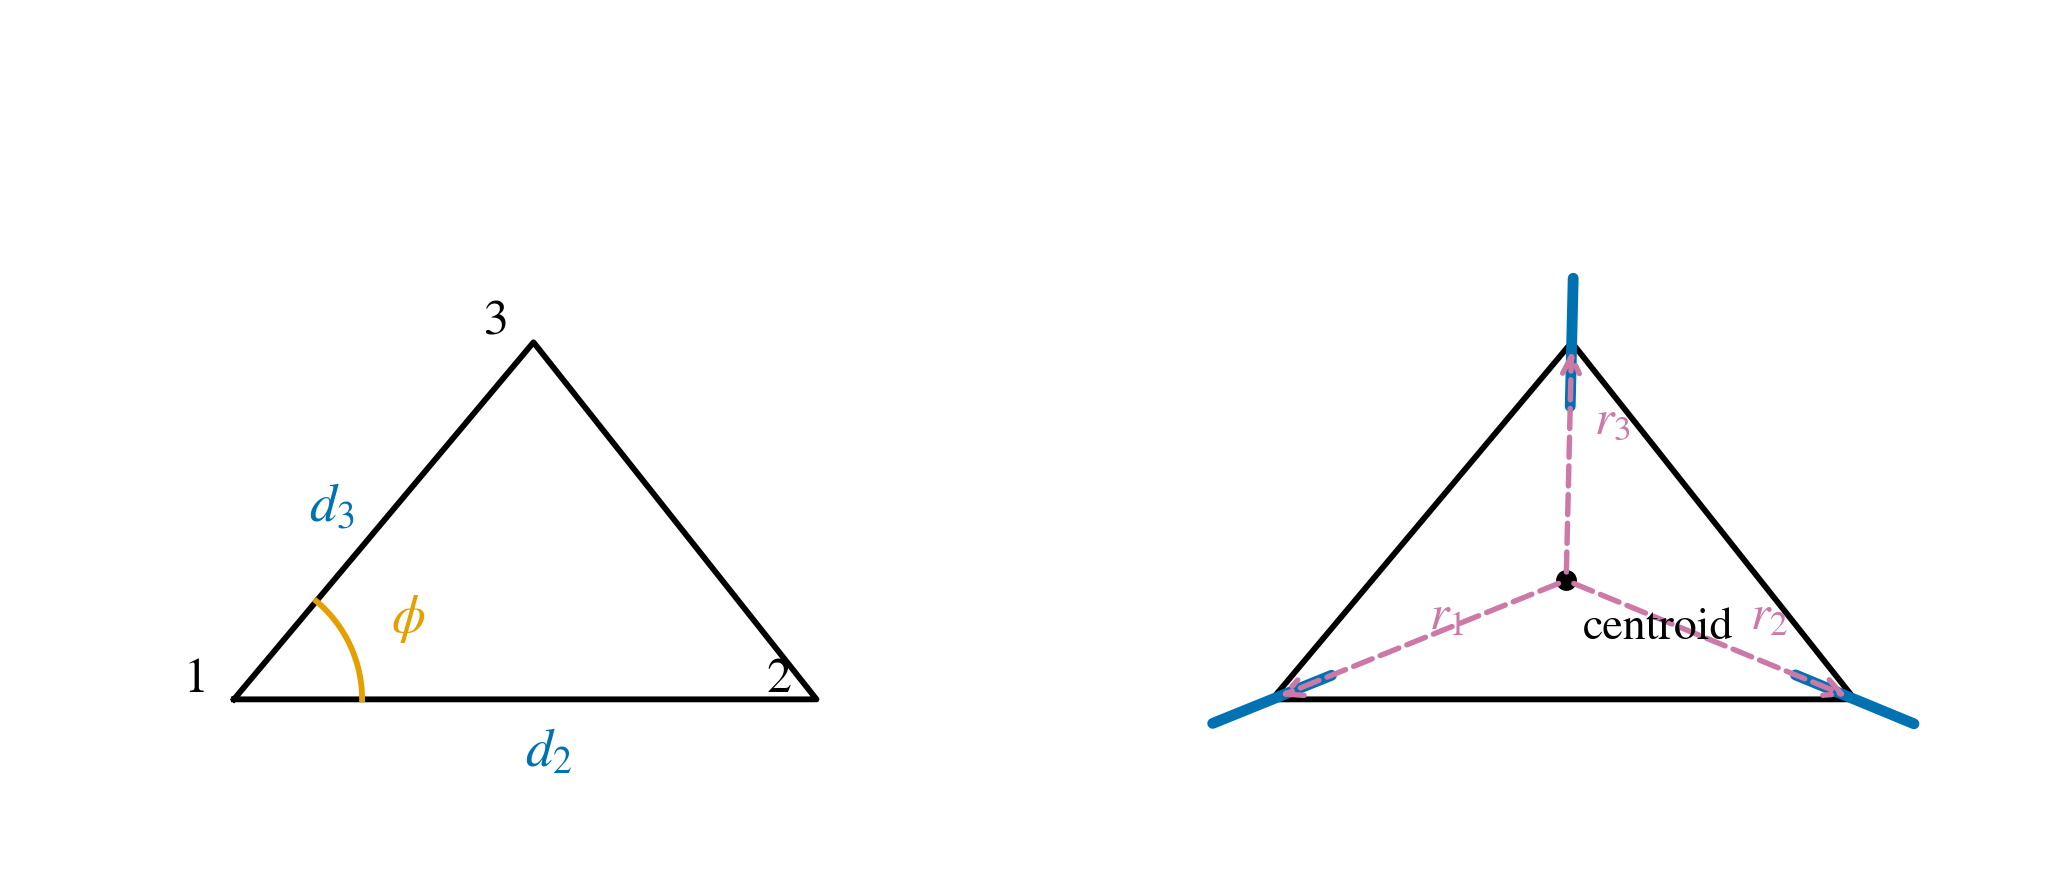

In [26]:
# The triangle of the geometry figure: d2 = 1 along the x axis and
# d3 = 0.8 at an opening angle of 50 degrees, a generic scalene shape.
opening = np.radians(50.0)
vertices = [[0.0, 0.0],
            [1.0, 0.0],
            [0.8 * np.cos(opening), 0.8 * np.sin(opening)]]
payload = {
    "about": "The side-angle-side labelling and the centroid "
             "construction of the note's finite-grid estimator, for a "
             "triangle with d2 = 1, d3 = 0.8 and phi = 50 degrees.  "
             "Written by the export cell of "
             "aperture_mass_statistic.ipynb, Section 9.",
    "vertices": vertices,
}
with open(NOTE / "plots/triangle_geometry/data.json", "w") as stream:
    json.dump(payload, stream)
run_plot("triangle_geometry")


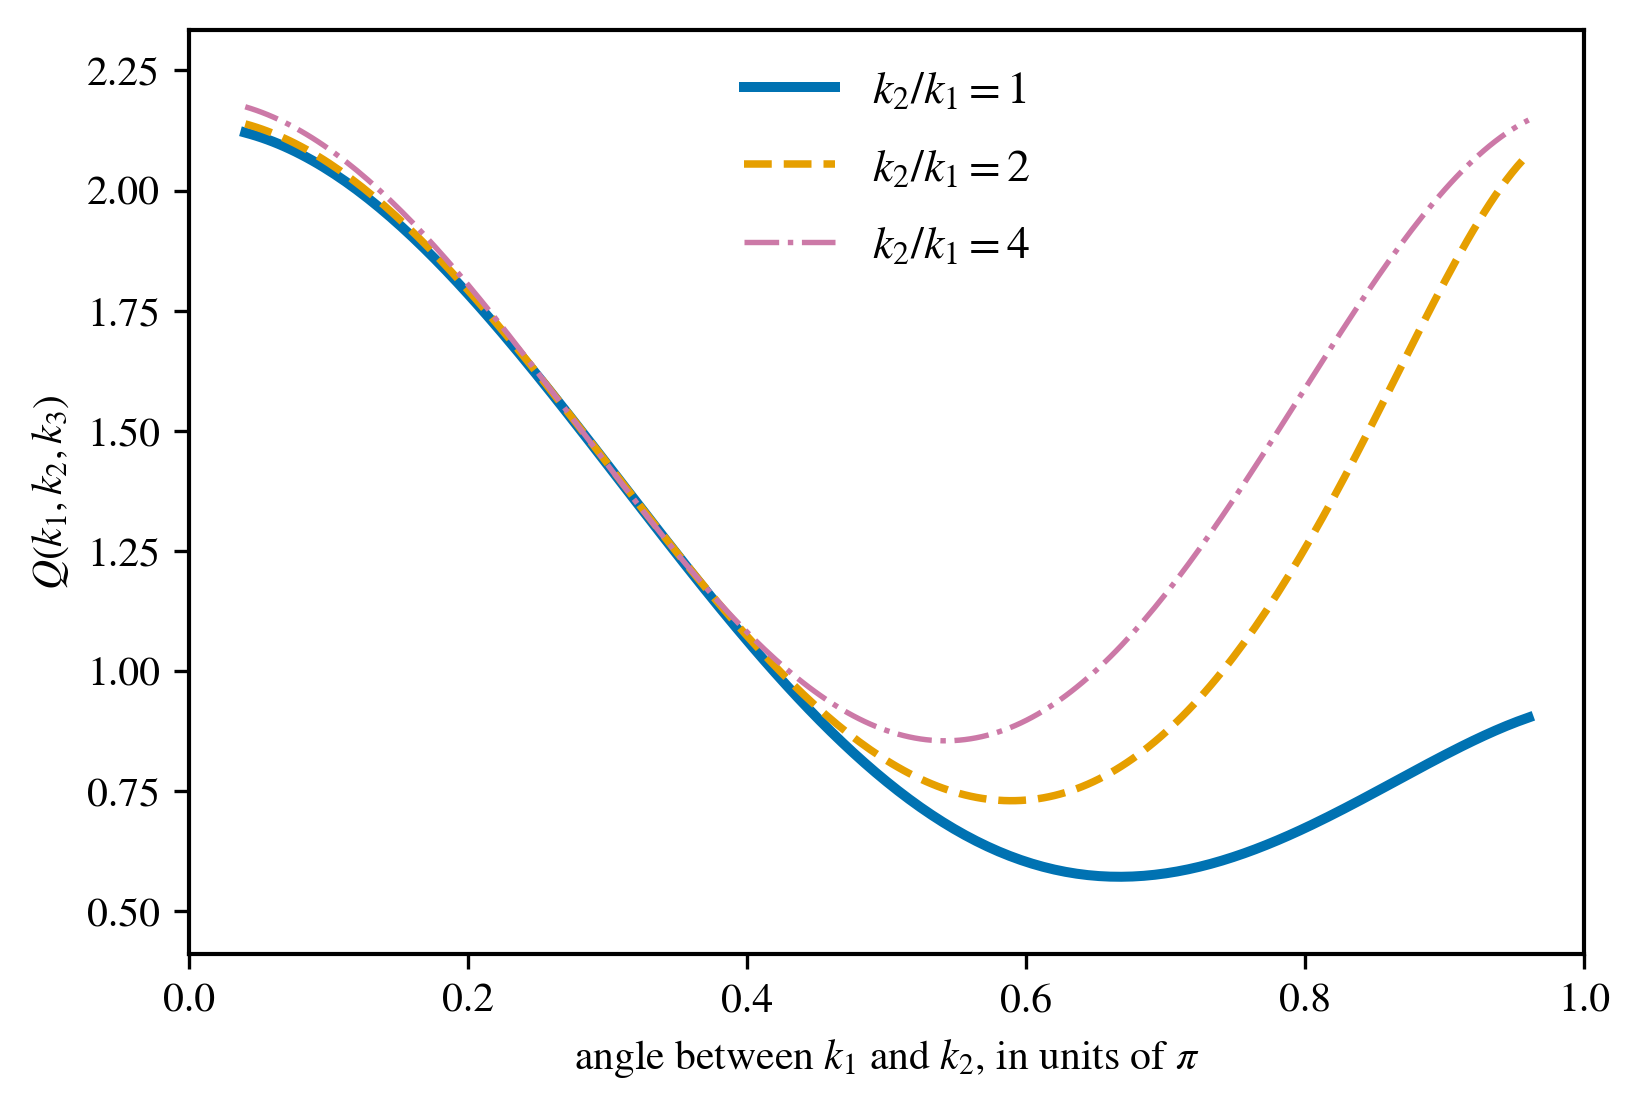

In [27]:
# The reduced tree-level bispectrum over triangle shapes, for a
# power-law toy spectrum P(k) = k^(-1.5).  The angle grid stays away
# from the collinear endpoints, where the squeezed limit diverges.
def kernel_f2(vector1, vector2):
    """The second-order gravity kernel F2 of the note's Eq. (3.17)."""
    length1 = np.hypot(vector1[0], vector1[1])
    length2 = np.hypot(vector2[0], vector2[1])
    mu = (vector1[0] * vector2[0] + vector1[1] * vector2[1]) \
        / (length1 * length2)
    return (5.0 / 7.0 + 0.5 * mu * (length1 / length2
            + length2 / length1) + 2.0 / 7.0 * mu**2)


def toy_power(wavenumber):
    return wavenumber**(-1.5)


angle_grid = np.pi * np.linspace(0.04, 0.96, 231)
side_ratios = [1.0, 2.0, 4.0]
curves = []
for ratio in side_ratios:
    row = []
    for phi in angle_grid:
        vector1 = np.array([1.0, 0.0])
        vector2 = ratio * np.array([np.cos(phi), np.sin(phi)])
        vector3 = -(vector1 + vector2)
        lengths = [1.0, ratio, np.hypot(vector3[0], vector3[1])]
        powers = [toy_power(length) for length in lengths]
        tree = (2.0 * kernel_f2(vector1, vector2) * powers[0] * powers[1]
                + 2.0 * kernel_f2(vector2, vector3) * powers[1] * powers[2]
                + 2.0 * kernel_f2(vector3, vector1) * powers[2] * powers[0])
        denominator = (powers[0] * powers[1] + powers[1] * powers[2]
                       + powers[2] * powers[0])
        row.append(tree / denominator)
    curves.append(row)

payload = {
    "about": "The reduced tree-level matter bispectrum Q = B_tree / "
             "(P1 P2 + P2 P3 + P3 P1) for a power-law toy spectrum "
             "P(k) = k^-1.5, against the angle between k1 and k2, for "
             "side ratios k2/k1 = 1, 2, 4.  Written by the export cell "
             "of aperture_mass_statistic.ipynb, Section 9.",
    "angle_over_pi": (angle_grid / np.pi).tolist(),
    "side_ratios": side_ratios,
    "reduced_bispectrum": curves,
}
with open(NOTE / "plots/bispectrum_shapes/data.json", "w") as stream:
    json.dump(payload, stream)
run_plot("bispectrum_shapes")


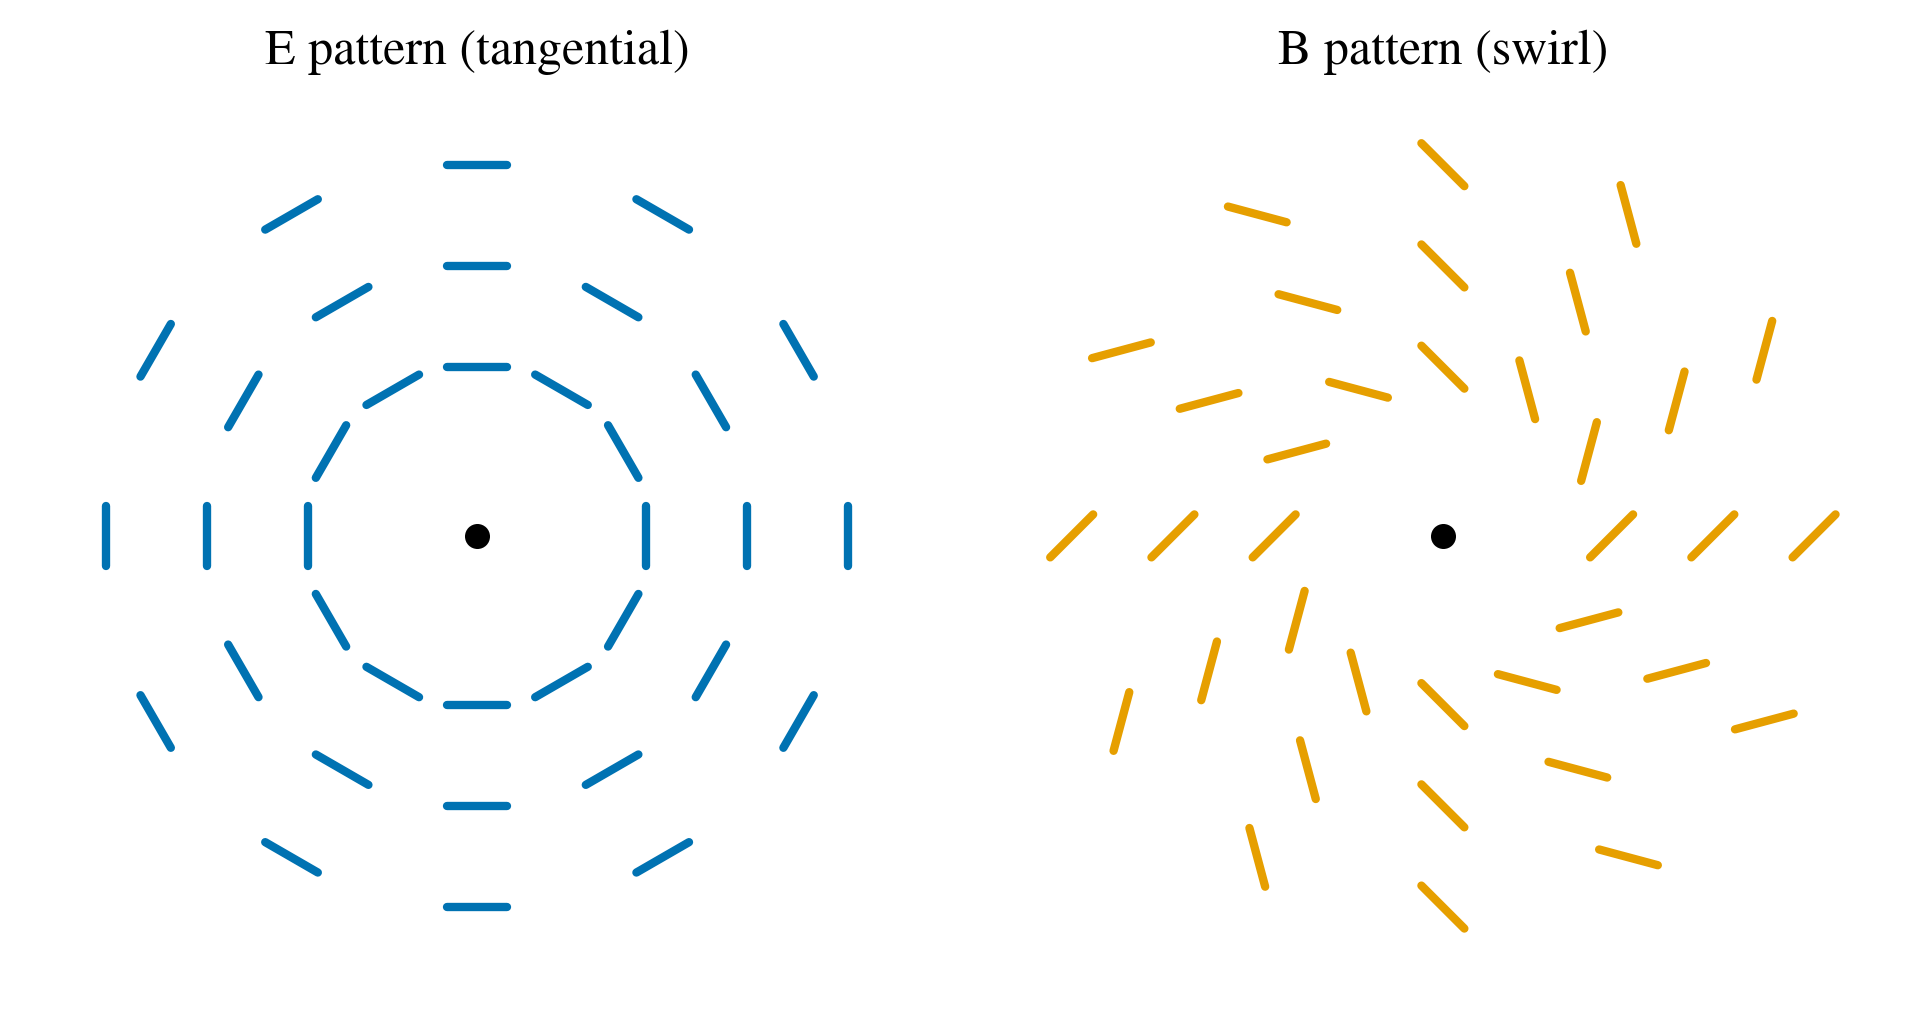

In [28]:
# The E/B patterns around a point: three rings of headless sticks,
# tangential for E and rotated by 45 degrees for B.
payload = {
    "about": "The E (tangential) and B (swirl) polarization patterns "
             "of a shear field around a point: stick positions on "
             "three rings; the script draws the tangential sticks and "
             "their 45-degree rotation.  Written by the export cell of "
             "aperture_mass_statistic.ipynb, Section 9.",
    "ring_radii": [0.5, 0.8, 1.1],
    "sticks_per_ring": 12,
    "stick_half_length": 0.09,
}
with open(NOTE / "plots/eb_patterns/data.json", "w") as stream:
    json.dump(payload, stream)
run_plot("eb_patterns")


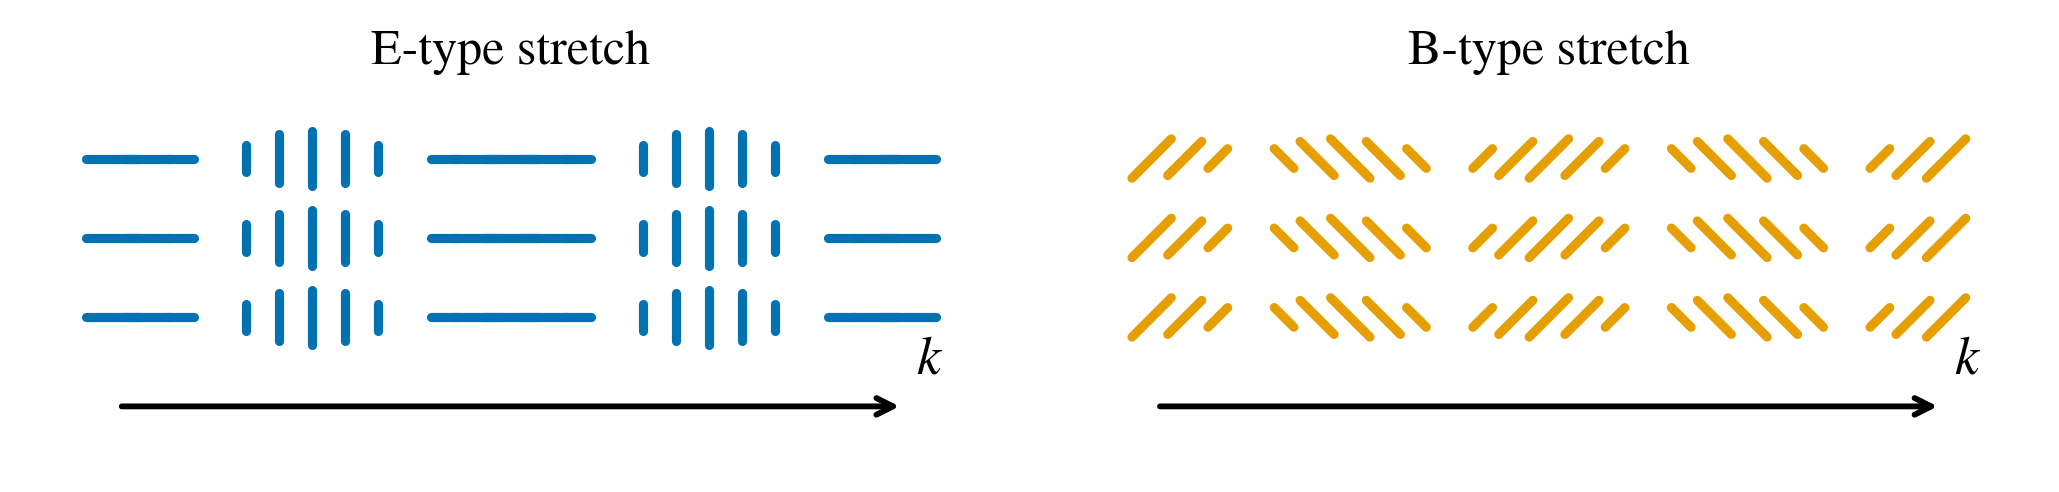

In [29]:
# The E-type against B-type stretch along one wavevector: stick
# positions over two wavelengths, three rows, amplitude following the
# wave.
payload = {
    "about": "The E-type (aligned/perpendicular) and B-type (45 "
             "degree) stretch patterns a shape mode can carry along a "
             "wavevector: stick positions over two wavelengths with "
             "the amplitude following the wave.  Written by the export "
             "cell of aperture_mass_statistic.ipynb, Section 9.",
    "positions": np.linspace(0.0, 2.0, 25).tolist(),
    "rows": [-0.2, 0.0, 0.2],
    "wavelength": 1.0,
    "stick_half_length": 0.07,
}
with open(NOTE / "plots/ia_bmode_geometry/data.json", "w") as stream:
    json.dump(payload, stream)
run_plot("ia_bmode_geometry")


## 10. The numbers the note quotes

Every number quoted in `aperture_mass_statistic.tex` is printed above:

- Section 2 (fiducial table, derived sigma8, TATT point, data layout):
  Sections 4 and 5;
- Section 5 (compensation, window peak $\sqrt{2}$ and $1/e$): Section 2;
- Section 6 (white-noise $\langle M_\mathrm{ap}^2 \rangle = A/(8\pi R^2)$,
  measured map variance against the formula): Sections 2 and 3;
- Sections 3-7 sanity checks (shear route, mass sheet, Gaussian skewness,
  the non-Gaussian toy's third moment): Section 3;
- Section 7 (the 20 triplets, 80 rows): Section 5;
- Section 9 (kernel-weight coverage of the measured side range): Section 8;
- Section 10 (side bins, cut, $\Delta\ln d$, angle bins, multipole caps,
  201 measurement multipoles): Sections 5 and 6;
- Section 11 (TATT point, operator split with its extreme values, closure
  identities, equilateral coefficients, $U$, $V$, $W$, $T$, the
  velocity-shear convention difference): Sections 7 and 8.

The figures are rebuilt by their export cells: `aperture_filter` and the map
figures `gaussian_map` and `toy_moments` (Sections 2-3), `map3_fiducial` and
`triangle_coverage` (Section 5), `map3_operators` and `ia_placements`
(Section 7), and the illustration figures `triangle_geometry`,
`bispectrum_shapes`, `eb_patterns` and `ia_bmode_geometry` (Section 9).
Each `plots/<name>/plot_<name>.py` redraws its figure from `data.json`
alone.
